# Аналитика выдач команды продаж: залоговые и беззалоговые займы (Астана, 2023–2026)

**Заказчик:** руководитель направления розничных продаж.
**Бизнес-проблема:** за январь–сентябрь 2026 года команда выдала на **43% меньше**, чем годом ранее. Нужно понять, что сломалось, и что делать с этим в 4 квартале.

Данные: 4 049 выдач, январь 2023 – 12 октября 2026. Менеджеры и клиенты обезличены, фамилии синтетические.

## Оглавление
1. [Постановка задачи](#1)
2. [Сбор данных: SQL](#2)
3. [Предобработка](#3)
4. [Исследовательский анализ (EDA)](#4)
5. [Метрики: разложение падения, когорты, юнит-экономика](#5)
6. [Прогноз: линейная регрессия](#6)
7. [Проверка гипотез](#7)
8. [Дашборд](#8)
9. [Выводы и рекомендации](#9)

<a id="1"></a>
## 1. Постановка задачи

| | |
|---|---|
| **Цель** | Найти причины падения выдач в 2026 году и дать план на 4 квартал |
| **Стейкхолдеры** | Руководитель продаж (решения по команде и каналам), менеджеры по продажам, партнёрский отдел (застройщики), риск-менеджмент (политика беззалоговых займов) |
| **KPI** | Объём выдач, ₸ · количество выдач · средний чек · выдач на менеджера в месяц · доля залоговых · доля канала застройщиков |

**Три главные гипотезы**
- **H1.** Падение вызвано командой: стало меньше людей или больше новичков (§5.1, §5.2).
- **H2.** Падение сосредоточено в беззалоговых займах, а залоговые держатся (§5.1). Сравниваем только по продукту: канал/партнёр указан не во всех заявках.
- **H3.** Спад сезонный: начало года всегда слабое, и во втором полугодии объём восстановится (§7).

**Дополнительные проверки** (§7): упал ли средний чек; нужен ли новичкам разгон; есть ли «дожим» плана в конце месяца; крупнее ли сделки через застройщиков.

<a id="2"></a>
## 2. Сбор данных: SQL

Excel-выгрузка загружается в SQLite скриптом `src/build_db.py` (таблицы `loans`, `managers`, `dim_source_product`, `source_monthly`, `date_adjustments`). Все запросы — в [`sql/queries.sql`](../sql/queries.sql): CTE, `JOIN`, оконные функции `LAG`, `RANK`, `SUM() OVER`.

In [1]:
from pathlib import Path
import sys, sqlite3, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import sql_utils as sq

# Шрифт: первый установленный из списка (Inter / Segoe UI / Arial содержат знак ₸), без предупреждений findfont
import logging
from matplotlib import font_manager
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
_installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Inter", "Segoe UI", "Arial", "DejaVu Sans"] if f in _installed), "sans-serif")

# Единый стиль графиков
plt.style.use("seaborn-v0_8-whitegrid")
PAL = {"Залоговый займ": "#2a78d6", "Беззалоговый займ": "#eb6834"}
C3 = "#1baf7a"
plt.rcParams.update({"figure.figsize": (11, 4.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e6e5e0",
                     "legend.frameon": False, "lines.linewidth": 2,
                     "font.family": FONT})
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)
bn = lambda x: x / 1e9   # млрд тенге
mln = lambda x: x / 1e6  # млн тенге
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(f"pandas {pd.__version__} | seaborn {sns.__version__} | шрифт графиков: {FONT}")

pandas 2.3.3 | seaborn 0.13.2 | шрифт графиков: Segoe UI


In [2]:
DB = ROOT / "data" / "processed" / "loans.sqlite"
if not DB.exists():
    import build_db; build_db.main()
with sqlite3.connect(DB) as con:
    raw = pd.read_sql_query("SELECT * FROM loans", con)
    dim = pd.read_sql_query("SELECT * FROM dim_source_product", con)
rec = sq.run("reconciliation")
print(f"Строк в детализации: {len(raw):,}")
print(f"Сверка с итогами отчёта: месяцев×продуктов {len(rec)}, расхождений по штукам {(rec.diff_cnt != 0).sum()}, "
      f"по сумме {rec.diff_amount.abs().sum():,.0f} ₸")

БД готова: data\processed\loans.sqlite | loans=4,049 | managers=30 | dim_source_product=134
Строк в детализации: 4,049
Сверка с итогами отчёта: месяцев×продуктов 90, расхождений по штукам 0, по сумме 0 ₸


**Вывод:** детализация полностью сходится с итогами исходного отчёта: 90 комбинаций «месяц × продукт», 0 расхождений по количеству и по сумме. Итоговые строки менеджеров (213 шт.) были исключены ещё при подготовке выгрузки, так что двойного счёта нет.

<a id="3"></a>
## 3. Предобработка

In [3]:
df = raw.copy()
before = len(df)
log = []

# 1. Типы
df["issue_date"] = pd.to_datetime(df["issue_date"])
df["amount_kzt"] = df["amount_kzt"].astype("int64")
for c in ["product", "manager_id", "date_quality"]:
    df[c] = df[c].astype("category")

# 2. Полные дубли и дубли по смысловому ключу
full_dup = df.drop(columns="loan_id").duplicated().sum()
key_dup = df.duplicated(["client_id", "issue_date", "product", "amount_kzt"]).sum()
df = df.drop_duplicates(subset=["client_id", "issue_date", "product", "amount_kzt"])
log.append(("Дубли (клиент+дата+продукт+сумма)", key_dup))

# 3. Пропуски: подпись продукта из источника есть не всегда -> отдельная категория
na_src = df["source_product_raw"].isna().sum()
df = df.merge(dim, on="source_product_raw", how="left")
df["channel"] = df["channel"].fillna("Не указано")
df["developer"] = df["developer"].fillna("—")

# 4. Аномалии
neg = (df["amount_kzt"] <= 0).sum()
q = df.groupby("product", observed=True)["amount_kzt"].quantile([.25, .75]).unstack()
iqr_hi = (q[0.75] + 3 * (q[0.75] - q[0.25])).rename("hi")
df = df.join(iqr_hi, on="product")
df["is_outlier"] = df["amount_kzt"] > df["hi"]
df = df.drop(columns="hi")
df["is_cond_date"] = df["date_quality"].astype(str).str.contains("Условн|Смоделир")
df["weekday"] = df["issue_date"].dt.dayofweek
df["is_weekend"] = df["weekday"] >= 5
month_mismatch = ((df.issue_date.dt.year != df.year) | (df.issue_date.dt.month != df.month)).sum()

# 5. Признаки
df["ym"] = df["issue_date"].dt.to_period("M")
df["dom"] = df["issue_date"].dt.day
df["days_in_month"] = df["issue_date"].dt.days_in_month
df["is_last5"] = df["days_in_month"] - df["dom"] < 5
df["amount_mln"] = mln(df["amount_kzt"])
df["is_secured"] = (df["product"] == "Залоговый займ").astype(int)

quality = pd.DataFrame([
    ("Строк до очистки", before),
    ("Полных дублей", full_dup),
    ("Дублей по ключу клиент+дата+продукт+сумма", key_dup),
    ("Пропуски «Продукт_из_источника» → «Не указано»", na_src),
    ("Нулевые/отрицательные суммы", neg),
    ("Выбросы > Q3+3·IQR (оставлены, помечены)", int(df.is_outlier.sum())),
    ("Условные/смоделированные даты (исключаем из дневного анализа)", int(df.is_cond_date.sum())),
    ("Выдачи в выходные (оставлены)", int(df.is_weekend.sum())),
    ("Дата не совпадает с месяцем отчёта", month_mismatch),
    ("Строк после очистки", len(df)),
], columns=["Проверка", "Значение"])
print(f"Потеряно при очистке: {before - len(df)} строк ({(before - len(df)) / before:.2%})")
quality

Потеряно при очистке: 0 строк (0.00%)


,Проверка,Значение
0,Строк до очистки,4049
1,Полных дублей,0
2,Дублей по ключу клиент+дата+продукт+сумма,0
3,Пропуски «Продукт_из_источника» → «Не указано»,1284
4,Нулевые/отрицательные суммы,0
5,"Выбросы > Q3+3·IQR (оставлены, помечены)",37
6,Условные/смоделированные даты (исключаем из дн...,24
7,Выдачи в выходные (оставлены),51
8,Дата не совпадает с месяцем отчёта,0
9,Строк после очистки,4049


**До и после:** 4 049 → 4 049 строк, потеряно **0%**. Дублей нет, сумм ≤ 0 нет. Ничего не удаляем, только помечаем:
- 1 284 пропуска в подписи продукта (почти все в 2023 году) заполнены категорией «Не указано», а 134 варианта ручного ввода («биай», «BI», «би ай»…) сведены в справочник каналов и застройщиков;
- 37 крупных выдач (до 100 млн ₸) — это реальные залоговые сделки, их оставляем и помечаем флагом;
- 24 условные или смоделированные даты исключаем только из анализа по дням.

Месяцы с незакрытой вакансией: 2023-01, 2023-02, 2023-10, 2023-11, 2024-06, 2025-04, 2025-05, 2026-08, 2026-10


,менеджеров за год,наняты в году,ушли в году,текучесть,укомплектованность штата
2023,7,7,7,1.00,0.94
2024,9,9,9,1.00,0.99
2025,10,10,4,0.40,0.97
2026,8,2,2,0.25,0.97


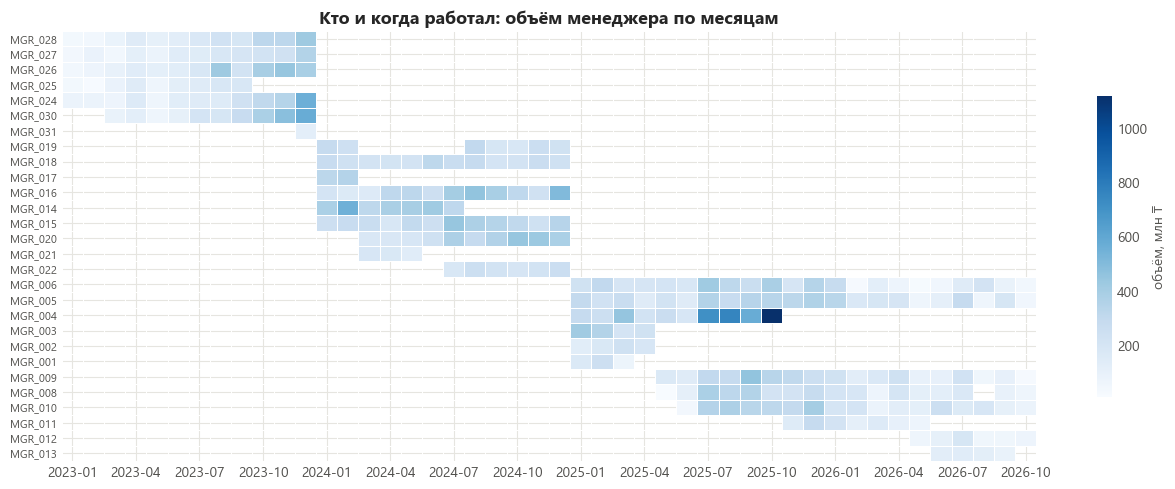

In [4]:
# Проверка идентификаторов: менеджеры — реальные сотрудники (увольнения и найм), клиенты — синтетические ID
mm0 = df.groupby(["manager_id", "ym"], observed=True).amount_kzt.sum().unstack(fill_value=0)
mm0 = mm0.loc[mm0.gt(0).idxmax(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(mln(mm0).replace(0, np.nan), cmap="Blues", ax=ax, cbar_kws={"label": "объём, млн ₸", "shrink": .7},
            linewidths=.5, linecolor="white", yticklabels=True)
ax.tick_params(axis="y", labelsize=8)
ax.set_xticks(np.arange(0, mm0.shape[1], 3) + .5); ax.set_xticklabels([str(c) for c in mm0.columns[::3]], rotation=0)
ax.set(title="Кто и когда работал: объём менеджера по месяцам", xlabel="", ylabel="")
plt.tight_layout(); fig.savefig(IMG / "00_team_timeline.png", dpi=150, bbox_inches="tight")

act = df.groupby("manager_id", observed=True).agg(first=("ym", "min"), last=("ym", "max"))
turn = pd.DataFrame({y: {"менеджеров за год": ((act["first"].dt.year <= y) & (act["last"].dt.year >= y)).sum(),
                         "наняты в году": (act["first"].dt.year == y).sum(),
                         "ушли в году": ((act["last"].dt.year == y) & (act["last"] < df.ym.max())).sum()}
                     for y in range(2023, 2027)}).T
turn["текучесть"] = turn["ушли в году"] / turn["менеджеров за год"]

# Утверждённый штат: 6 менеджеров, с мая 2026 года — 7
STAFF = lambda p: 7 if p >= pd.Period("2026-05", "M") else 6
act_m = df.groupby("ym").manager_id.nunique()
staffing = pd.DataFrame({"активных": act_m, "штат": [STAFF(p) for p in act_m.index]})
st_y = staffing.groupby(staffing.index.year).sum()
turn["укомплектованность штата"] = st_y["активных"] / st_y["штат"]
print("Месяцы с незакрытой вакансией:", ", ".join(str(p) for p in staffing.index[staffing["активных"] < staffing["штат"]]))
turn

**Вывод (менеджеры):** ID — это реальные сотрудники, смена ID означает увольнение и найм. Утверждённый штат — 6 менеджеров, с мая 2026 года — 7; он укомплектован на 94–99% каждый год, вакансии закрывались за 1–2 месяца. Поэтому «менеджеров за год» больше штата: через команду проходят и ушедшие, и пришедшие им на смену. Команда **полностью сменилась дважды**, на рубеже 2023/24 и 2024/25 годов (текучесть 100%). В 2025 году ушли 4 из 10, в 2026 году — 2 из 8. Значит, нынешняя команда 2026 года — самая опытная за весь период, и падение не объясняется новичками.

In [5]:
# Клиенты: ID повторяется, когда клиент обращается снова. Проверим, в какие периоды это вообще видно.
cid = df[df.client_id.str.startswith("CL_")].copy()
cid["num"] = cid.client_id.str[3:].astype(int)
by_m = cid.groupby("ym").agg(loans=("loan_id", "size"), min_id=("num", "min"), max_id=("num", "max"),
                            clients=("client_id", "nunique"))
by_m["prev_max"] = by_m.max_id.cummax().shift()
by_m["все ID новые"] = by_m.min_id > by_m.prev_max        # ни один клиент месяца не встречался раньше
rep_y = df.groupby(["year", "client_id"]).size().gt(1).groupby("year").agg(["sum", "size", "mean"])
rep_y.columns = ["повторных клиентов", "клиентов", "доля повторных"]
print(rep_y.to_string(formatters={"доля повторных": "{:.1%}".format}))
new_only = by_m.index[by_m["все ID новые"]]
print(f"\nМесяцы, где все ID клиентов новые (повторов нет или они не связаны): {new_only.min()} … {new_only.max()} "
      f"({len(new_only)} мес. подряд)")

      повторных клиентов  клиентов доля повторных
year                                             
2023                   1      1124           0.1%
2024                   4      1400           0.3%
2025                 142       919          15.5%
2026                   0       426           0.0%

Месяцы, где все ID клиентов новые (повторов нет или они не связаны): 2025-10 … 2026-10 (13 мес. подряд)


**Скептицизм, или где подвох (клиенты):** повторный клиент получает тот же ID. В январе–сентябре 2025 года повторные обращения хорошо видны (142 клиента). Но **с октября 2025 года каждая выдача получает новый, следующий по счёту ID**, и ни один клиент не совпадает с прошлыми. Либо повторные клиенты действительно перестали возвращаться, либо с этого момента выгрузка не связывает клиентов. В 2023–2024 годах ID формировались по месяцам, и повторы тоже почти не видны. Поэтому retention клиентов считаем на окне январь–сентябрь 2025 (§5.4), а вывод про 2026 год даём с оговоркой.

<a id="4"></a>
## 4. Исследовательский анализ (EDA)
### 4.1 Динамика по годам

Последняя дата в данных: 12.10.2026


,cnt,yoy_amount,yoy_cnt,amount_bn
year,,,,
2023,758,NaN,NaN,6.76
2024,1042,1.22,0.37,15.04
2025,811,-0.04,-0.22,14.38
2026,414,-0.43,-0.49,8.25


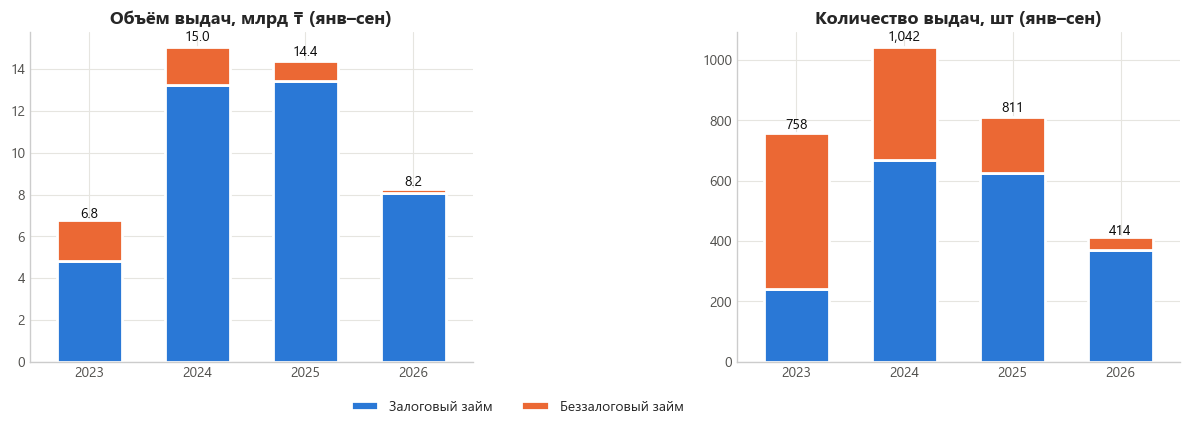

In [6]:
# Год к году на сопоставимом периоде: данные 2026 заканчиваются 12.10.2026,
# поэтому октябрь неполный и сравниваем январь–сентябрь
print(f"Последняя дата в данных: {df.issue_date.max():%d.%m.%Y}")
ytd = df[df.month <= 9]
yr = (ytd.groupby(["year", "product"], observed=True)
         .agg(cnt=("loan_id", "size"), amount=("amount_kzt", "sum"), ticket=("amount_kzt", "median"))
         .reset_index())
tot = ytd.groupby("year").agg(cnt=("loan_id", "size"), amount=("amount_kzt", "sum"))
tot["yoy_amount"] = tot.amount.pct_change()
tot["yoy_cnt"] = tot.cnt.pct_change()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
piv_a = yr.pivot(index="year", columns="product", values="amount").reindex(columns=list(PAL))
piv_c = yr.pivot(index="year", columns="product", values="cnt").reindex(columns=list(PAL))
bn(piv_a).plot.bar(stacked=True, ax=ax[0], color=PAL.values(), width=.6, edgecolor="white", linewidth=2)
piv_c.plot.bar(stacked=True, ax=ax[1], color=PAL.values(), width=.6, edgecolor="white", linewidth=2, legend=False)
ax[0].set(title="Объём выдач, млрд ₸ (янв–сен)", xlabel="", ylabel="")
ax[1].set(title="Количество выдач, шт (янв–сен)", xlabel="", ylabel="")
for a, s, f in [(ax[0], bn(tot.amount), "{:.1f}"), (ax[1], tot.cnt, "{:,.0f}")]:
    for i, v in enumerate(s):
        a.text(i, v * 1.02, f.format(v), ha="center", fontsize=10, color="#0b0b0b")
    a.tick_params(axis="x", rotation=0)
ax[0].legend(title="", loc="upper center", bbox_to_anchor=(1.1, -0.08), ncol=2)
plt.tight_layout(); fig.savefig(IMG / "01_yearly.png", dpi=150, bbox_inches="tight")
tot.assign(amount_bn=bn(tot.amount)).drop(columns="amount")

**Вывод:** 2024 год стал пиковым (+122% к 2023 году за январь–сентябрь), 2025 год прошёл на плато (−4%), а в 2026 году объём упал на **43%**, количество выдач — на **49%**. Падение по штукам глубже, чем по деньгам, то есть сокращаются в первую очередь мелкие сделки.

Доля залоговых в объёме: 2023 — 71%, 2026 — 98% (средняя по месяцам)


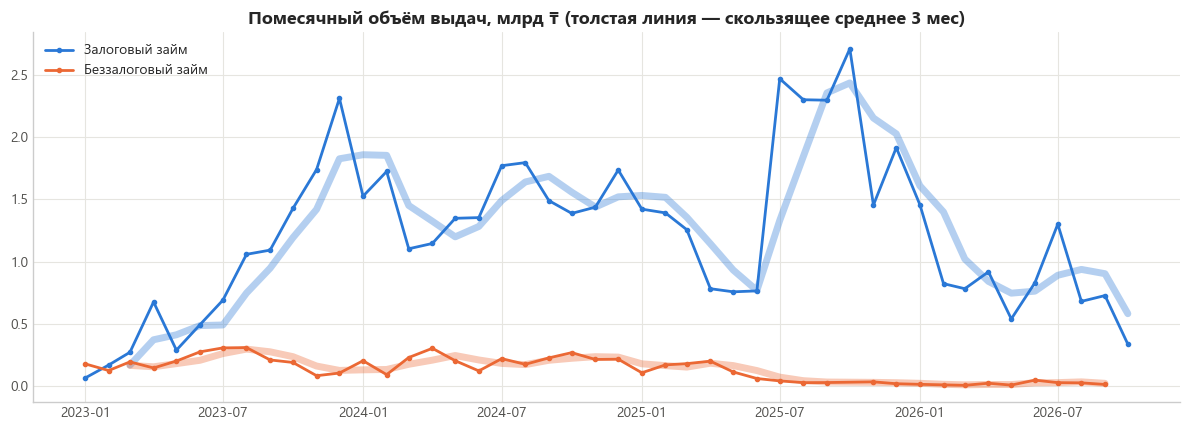

In [7]:
mk = sq.run("monthly_kpi")
mk["date"] = pd.to_datetime(mk.ym)
fig, ax = plt.subplots(figsize=(12, 4.4))
for p, c in PAL.items():
    s = mk[mk["product"] == p].set_index("date")["amount_kzt"]
    ax.plot(s.index, bn(s), color=c, label=p, marker="o", markersize=3)
    ax.plot(s.index, bn(s.rolling(3).mean()), color=c, alpha=.35, linewidth=5)
ax.set(title="Помесячный объём выдач, млрд ₸ (толстая линия — скользящее среднее 3 мес)", ylabel="")
ax.legend(loc="upper left")
plt.tight_layout(); fig.savefig(IMG / "02_monthly.png", dpi=150, bbox_inches="tight")

share = mk.pivot(index="ym", columns="product", values="share_in_month")["Залоговый займ"]
print(f"Доля залоговых в объёме: 2023 — {share[share.index.str[:4]=='2023'].mean():.0%}, "
      f"2026 — {share[share.index.str[:4]=='2026'].mean():.0%} (средняя по месяцам)")

**Вывод:** весной 2025 года уже был провал (апрель–июнь), но с июля команда отыгралась до рекордных 2,3–2,7 млрд ₸ в месяц. В 2026 году такого отскока нет: после января объём держится на уровне 0,5–1,3 млрд ₸. Беззалоговые займы сходят на нет с середины 2024 года, и в 2026 году залог даёт **98%** объёма (в 2023 году было 71%).

count  mean   50%    max
product           year                          
Беззалоговый займ 2023 609.00  3.80  3.60   9.00
                  2024 522.00  4.80  4.60  21.10
                  2025 199.00  5.00  4.70  32.50
                  2026  43.00  4.20  4.00   8.00
Залоговый займ    2023 516.00 19.90 18.00  91.00
                  2024 882.00 20.20 18.10  80.00
                  2025 895.00 21.80 19.10 100.00
                  2026 383.00 21.90 19.10 100.00

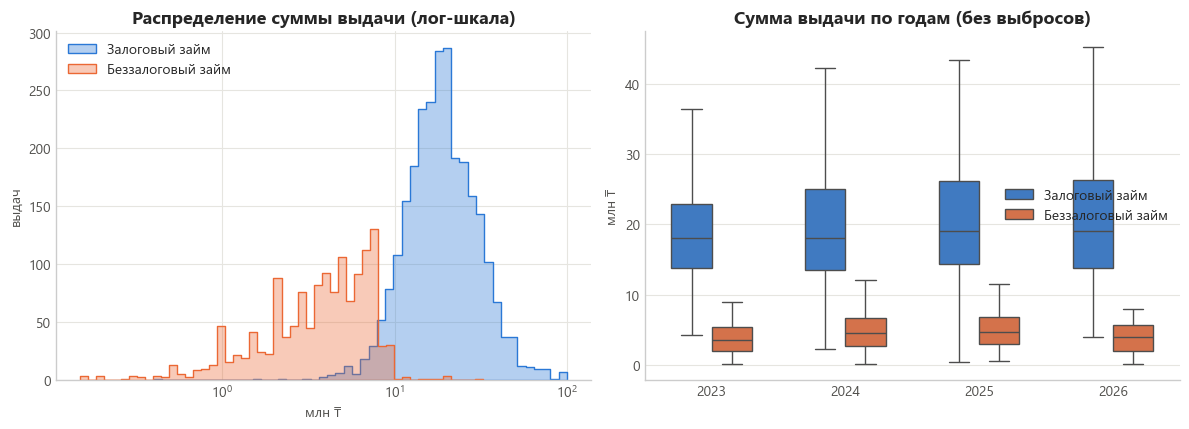

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for p, c in PAL.items():
    sns.histplot(df.loc[df["product"] == p, "amount_mln"], bins=50, log_scale=True, color=c, label=p,
                 ax=ax[0], element="step", alpha=.35)
ax[0].set(title="Распределение суммы выдачи (лог-шкала)", xlabel="млн ₸", ylabel="выдач")
ax[0].legend()
sns.boxplot(data=df, x="year", y="amount_mln", hue="product", palette=PAL, ax=ax[1], showfliers=False,
            hue_order=list(PAL), width=.6, linewidth=1)
ax[1].set(title="Сумма выдачи по годам (без выбросов)", xlabel="", ylabel="млн ₸")
ax[1].legend(title="")
plt.tight_layout(); fig.savefig(IMG / "03_distribution.png", dpi=150, bbox_inches="tight")
(df.groupby(["product", "year"], observed=True)["amount_mln"]
   .describe(percentiles=[.5])[["count", "mean", "50%", "max"]].round(1))

**Вывод:** залоговая выдача примерно в 5 раз крупнее беззалоговой (медиана 18–19 млн ₸ против 4–5 млн ₸). Медианный залоговый чек стабилен с 2023 года, так что рост «среднего чека команды» объясняется сменой продуктового микса, а не тем, что сделки стали крупнее.

channel,Партнёр-застройщик,Стандарт (без партнёра),Не указано,Цифровая ипотека (ЦИ),Вторичное жильё,Под собственный залог,Госпрограмма 7-20-25,Прочее / нераспознано,Беззалоговый: БЗК/рефинанс
year,,,,,,,,,
2023,40.30,25.40,31.60,0.00,0.00,0.00,0.60,2.10,0.00
2024,68.80,16.90,10.00,0.00,2.30,0.60,1.10,0.00,0.30
2025,59.60,13.30,7.50,6.90,10.20,1.10,1.10,0.10,0.20
2026,58.50,9.70,6.00,21.70,0.50,3.70,0.00,0.00,0.00


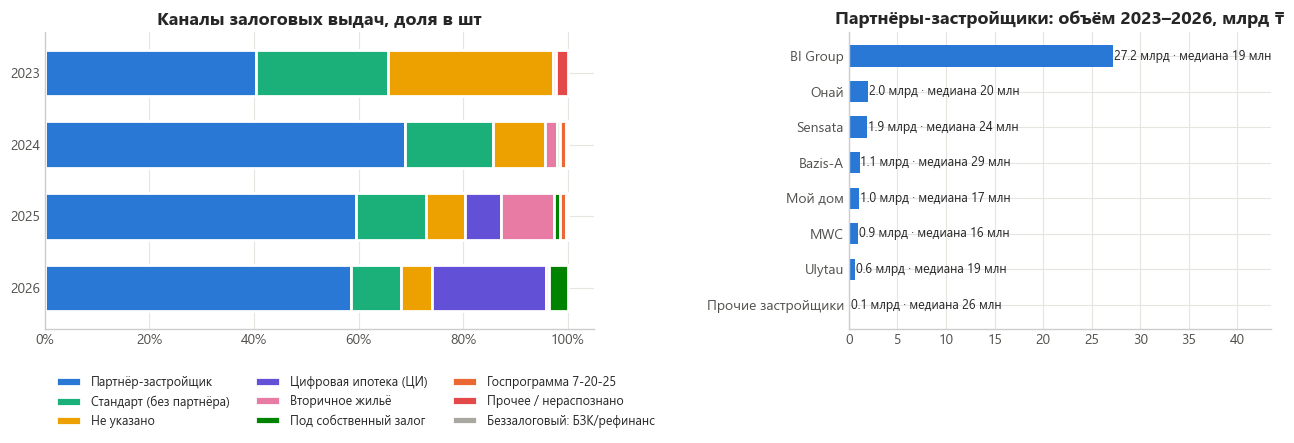

In [9]:
sec = df[df["product"] == "Залоговый займ"]
ch = pd.crosstab(sec.year, sec.channel, normalize="index")
order = ch.mean().sort_values(ascending=False).index
ch = ch[order]
cols = ["#2a78d6", "#1baf7a", "#eda100", "#6250d6", "#e87ba4", "#008300", "#eb6834", "#e34948", "#a8a7a0"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ch.plot.barh(stacked=True, ax=ax[0], color=cols[:len(order)], width=.65, edgecolor="white", linewidth=2)
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].invert_yaxis()
ax[0].set(title="Каналы залоговых выдач, доля в шт", ylabel="", xlabel="")
ax[0].legend(bbox_to_anchor=(0, -0.12), loc="upper left", ncol=3, fontsize=9)
dev = (sec[sec.developer != "—"].groupby("developer")
          .agg(cnt=("loan_id", "size"), amount=("amount_kzt", "sum"), ticket=("amount_mln", "median"))
          .sort_values("amount"))
ax[1].barh(dev.index, bn(dev.amount), color="#2a78d6", height=.6)
for i, (v, t) in enumerate(zip(bn(dev.amount), dev.ticket)):
    ax[1].text(v + .1, i, f"{v:.1f} млрд · медиана {t:.0f} млн", va="center", fontsize=9)
ax[1].set(title="Партнёры-застройщики: объём 2023–2026, млрд ₸", xlabel="")
ax[1].set_xlim(0, bn(dev.amount).max() * 1.6)
plt.tight_layout(); fig.savefig(IMG / "04_channels.png", dpi=150, bbox_inches="tight")
(ch * 100).round(1)

**Вывод (по размеченным сделкам; в ≈30% выдач канал не указан, поэтому структура приблизительная):** около 60% залоговых сделок приходит через партнёров-застройщиков. Крупнейший из них, BI Group, даёт больше половины партнёрских выдач. Канал «Цифровая ипотека» появился в 2025 году и единственный растёт.

Пиковые месяцы: 7, 8, 10; провальные: 5, 3, 2
Выходные: 1.1% выдач; последние 5 дней месяца: 16.1%


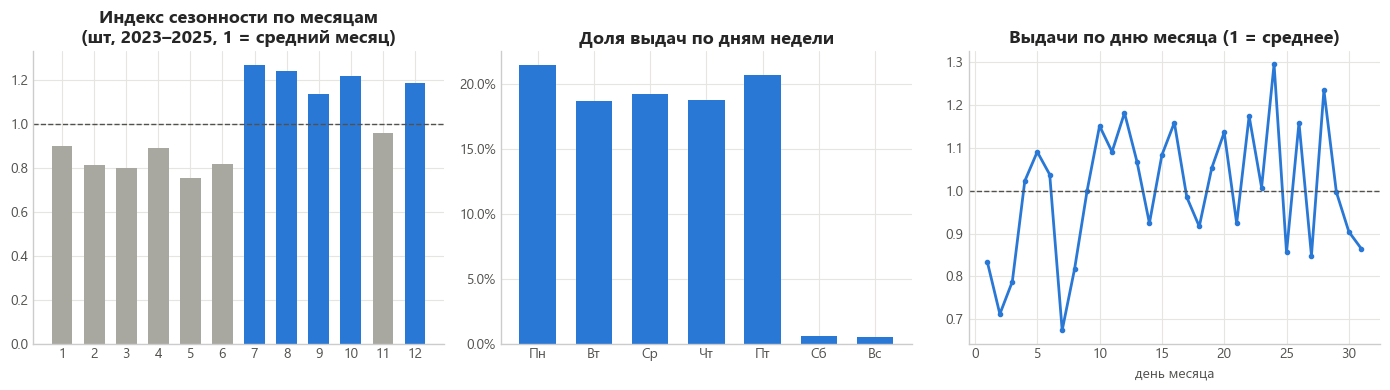

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
full = df[df.year <= 2025]
m_idx = full.groupby(["year", "month"]).size().groupby("year").transform(lambda s: s / s.mean())
m_idx = m_idx.groupby("month").mean()
ax[0].bar(m_idx.index, m_idx.values, color=["#2a78d6" if v >= 1 else "#a8a7a0" for v in m_idx.values], width=.65)
ax[0].axhline(1, color="#52514e", lw=1, ls="--")
ax[0].set(title="Индекс сезонности по месяцам\n(шт, 2023–2025, 1 = средний месяц)", xticks=range(1, 13))
clean = df[~df.is_cond_date]
wd = clean.weekday.value_counts(normalize=True).sort_index()
ax[1].bar(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], wd.values, color="#2a78d6", width=.65)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set(title="Доля выдач по дням недели")
# нормируем на число месяцев, в которых этот день есть (29–31 числа бывают не всегда)
months_with_day = pd.Series({d: (clean.drop_duplicates("ym").days_in_month >= d).sum() for d in range(1, 32)})
dm = clean.groupby("dom").size() / months_with_day
dm = dm / dm.mean()
ax[2].plot(dm.index, dm.values, color="#2a78d6", marker="o", markersize=3)
ax[2].axhline(1, color="#52514e", lw=1, ls="--")
ax[2].set(title="Выдачи по дню месяца (1 = среднее)", xlabel="день месяца")
plt.tight_layout(); fig.savefig(IMG / "05_seasonality.png", dpi=150, bbox_inches="tight")
print(f"Пиковые месяцы: {', '.join(map(str, m_idx.nlargest(3).index))}; провальные: {', '.join(map(str, m_idx.nsmallest(3).index))}")
print(f"Выходные: {clean.is_weekend.mean():.1%} выдач; последние 5 дней месяца: {clean.is_last5.mean():.1%}")

**Вывод:** год чётко делится пополам: в июле–октябре и декабре выдач на 15–27% больше среднего месяца, в январе–июне — на 10–25% меньше (минимум в мае). Почти все выдачи идут в будни (в выходные 1,1%). Выдачи равномерно распределены по дням месяца, всплеска в конце месяца не видно (проверим тестом в разделе 7).

Доля топ-2 менеджеров в объёме года: 2023: 41%, 2024: 36%, 2025: 40%, 2026: 37%


,managers,avg_mgr_month_mln,median_cnt
year,,,
2023,7,185.60,15.00
2024,9,286.00,19.00
2025,10,293.10,15.00
2026,8,134.10,6.50


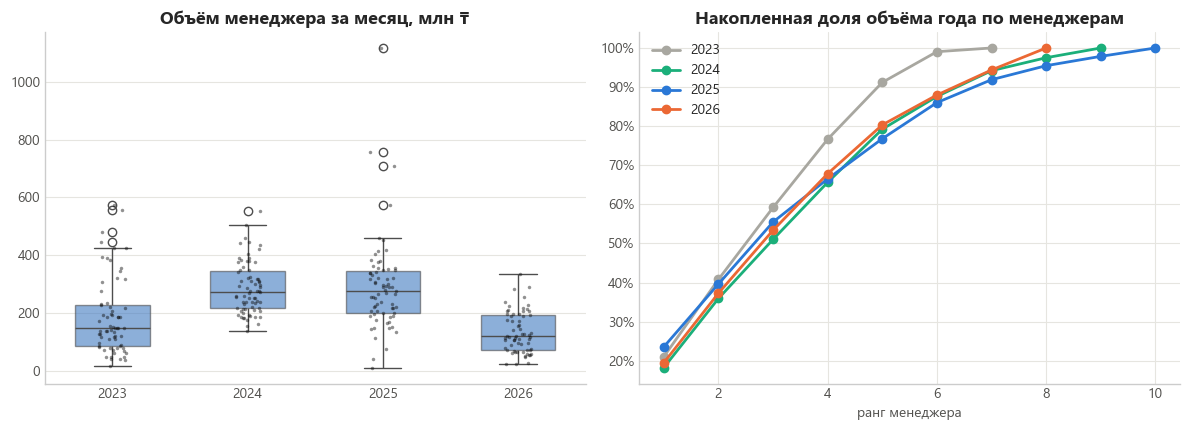

In [11]:
mm = sq.run("manager_month")
mm["period"] = np.where(mm.year >= 2025, "2025–26", mm.year.astype(str))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.boxplot(data=mm, x="year", y=mln(mm.amount_kzt), ax=ax[0], color="#2a78d6", width=.55, linewidth=1,
            boxprops=dict(alpha=.6))
sns.stripplot(data=mm, x="year", y=mln(mm.amount_kzt), ax=ax[0], color="#0b0b0b", size=2.5, alpha=.45)
ax[0].set(title="Объём менеджера за месяц, млн ₸", xlabel="", ylabel="")
par = sq.run("manager_pareto")
for y, c in zip(sorted(par.year.unique()), ["#a8a7a0", "#1baf7a", "#2a78d6", "#eb6834"]):
    p = par[par.year == y]
    ax[1].plot(range(1, len(p) + 1), p.cum_share, marker="o", color=c, label=str(y))
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set(title="Накопленная доля объёма года по менеджерам", xlabel="ранг менеджера", ylabel="")
ax[1].legend()
plt.tight_layout(); fig.savefig(IMG / "06_managers.png", dpi=150, bbox_inches="tight")
top2 = par[par.rnk <= 2].groupby("year").share.sum()
print("Доля топ-2 менеджеров в объёме года:", ", ".join(f"{y}: {v:.0%}" for y, v in top2.items()))
mm.groupby("year").agg(managers=("manager_id", "nunique"), avg_mgr_month_mln=("amount_kzt", lambda s: mln(s.mean())),
                       median_cnt=("cnt", "median")).round(1)

**Вывод:** одновременно работают 5–7 менеджеров при штате 6 (с мая 2026 года — 7), а за год из-за текучести через команду проходят 7–10 человек. Топ-2 менеджера стабильно дают **36–41%** объёма года, то есть уход одного сильного менеджера заметно бьёт по плану. В 2026 году средний объём менеджера в месяц упал вдвое: со ≈290 до **134 млн ₸**.

Объём ~ число залоговых: ρ=0.95; объём ~ число беззалоговых: ρ=0.00


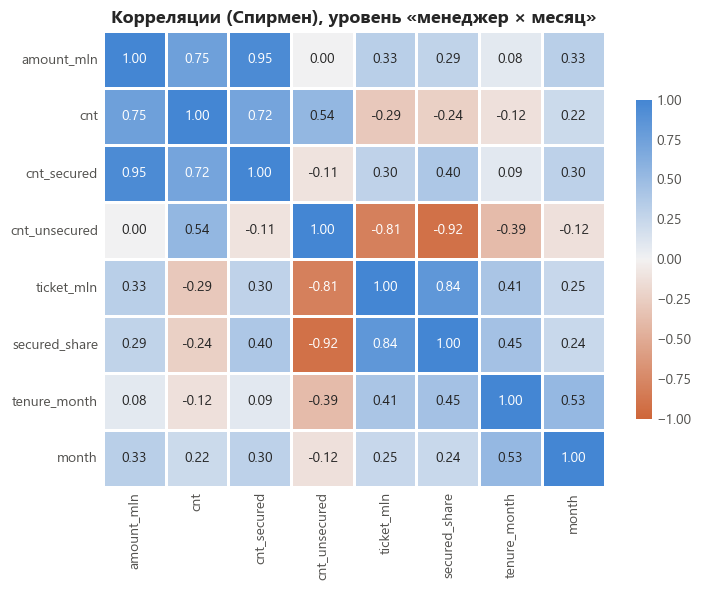

In [12]:
feat = mm.assign(amount_mln=mln(mm.amount_kzt), ticket_mln=mln(mm.avg_ticket_kzt),
                 secured_share=mm.cnt_secured / mm.cnt)[
    ["amount_mln", "cnt", "cnt_secured", "cnt_unsecured", "ticket_mln", "secured_share", "tenure_month", "month"]]
corr = feat.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(25, 250, s=80, l=55, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white", ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Корреляции (Спирмен), уровень «менеджер × месяц»")
plt.tight_layout(); fig.savefig(IMG / "07_corr.png", dpi=150, bbox_inches="tight")
print(f"Объём ~ число залоговых: ρ={corr.loc['amount_mln','cnt_secured']:.2f}; "
      f"объём ~ число беззалоговых: ρ={corr.loc['amount_mln','cnt_unsecured']:.2f}")

**Вывод:** объём менеджера почти полностью определяется числом залоговых сделок (ρ = 0,95). Беззалоговые займы на объём не влияют (ρ ≈ 0): это «штуки», а не деньги. Стаж с объёмом связан слабо.

In [13]:
# Профили выдач: чем отличается типичная залоговая и беззалоговая сделка
prof = df.groupby("product", observed=True).agg(
    выдач=("loan_id", "size"),
    доля_шт=("loan_id", lambda s: len(s) / len(df)),
    доля_объёма=("amount_kzt", lambda s: s.sum() / df.amount_kzt.sum()),
    медиана_млн=("amount_mln", "median"),
    p90_млн=("amount_mln", lambda s: s.quantile(.9)),
    в_выходные=("is_weekend", "mean"),
    через_застройщика=("channel", lambda s: (s == "Партнёр-застройщик").mean()))
prof.T

product,Беззалоговый займ,Залоговый займ
выдач,"1,373.00","2,676.00"
доля_шт,0.34,0.66
доля_объёма,0.10,0.90
медиана_млн,4.00,18.53
p90_млн,7.92,33.80
в_выходные,0.02,0.01
через_застройщика,0.00,0.59


**Вывод (профили сделок):** беззалоговые займы — это треть сделок, но лишь 10% объёма. Залоговые — две трети сделок и **90% объёма**, из них 59% приходит через застройщиков.

<a id="5"></a>
## 5. Метрики
### 5.1 Факторное разложение падения
Объём = менеджеро-месяцы × выдач на менеджеро-месяц × средний чек (логарифмическое разложение, январь–сентябрь).

,mgr_months,cnt,loans_per_mm,avg_ticket_mln,штатные_мм,укомплектованность,amount_bn
year,,,,,,,
2023,52,758,14.58,8.92,54,0.96,6.76
2024,53,1042,19.66,14.44,54,0.98,15.04
2025,52,811,15.60,17.73,54,0.96,14.38
2026,58,414,7.14,19.92,59,0.98,8.25


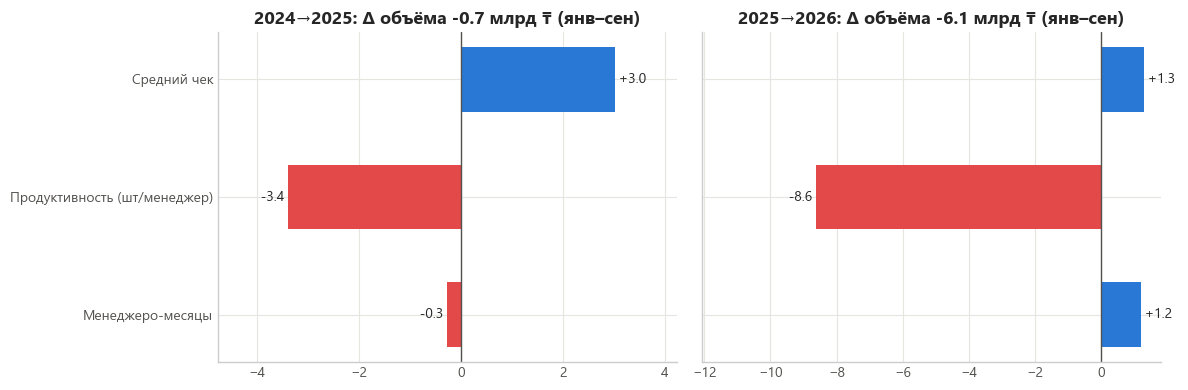

In [14]:
# Факторное разложение: Объём = менеджеро-месяцы × выдач на менеджеро-месяц × средний чек
mmy = mm[mm.month <= 9].groupby("year").agg(mgr_months=("ym", "size"), cnt=("cnt", "sum"), amount=("amount_kzt", "sum"))
mmy["loans_per_mm"] = mmy.cnt / mmy.mgr_months
mmy["avg_ticket_mln"] = mln(mmy.amount / mmy.cnt)
mmy["штатные_мм"] = [sum(STAFF(p) for p in pd.period_range(f"{y}-01", f"{y}-09", freq="M")) for y in mmy.index]
mmy["укомплектованность"] = mmy.mgr_months / mmy["штатные_мм"]
rows = []
for y0, y1 in [(2024, 2025), (2025, 2026)]:
    a, b = mmy.loc[y0], mmy.loc[y1]
    lnV = np.log(b.amount / a.amount)
    parts = {"Менеджеро-месяцы": np.log(b.mgr_months / a.mgr_months),
             "Продуктивность (шт/менеджер)": np.log(b.loans_per_mm / a.loans_per_mm),
             "Средний чек": np.log(b.avg_ticket_mln / a.avg_ticket_mln)}
    dV = b.amount - a.amount
    for k, v in parts.items():
        rows.append({"период": f"{y0}→{y1}", "фактор": k, "вклад_млрд": bn(dV * v / lnV)})
decomp = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (per, g) in zip(ax, decomp.groupby("период")):
    a.barh(g.фактор, g.вклад_млрд, color=["#2a78d6" if v > 0 else "#e34948" for v in g.вклад_млрд], height=.55)
    a.axvline(0, color="#52514e", lw=1)
    a.set_title(f"{per}: Δ объёма {g.вклад_млрд.sum():+.1f} млрд ₸ (янв–сен)")
    for i, v in enumerate(g.вклад_млрд):
        a.text(v, i, f" {v:+.1f} ", va="center", ha="left" if v > 0 else "right", fontsize=10)
    a.set_xlim(min(-1, g.вклад_млрд.min() * 1.4), max(1, g.вклад_млрд.max() * 1.4))
plt.tight_layout(); fig.savefig(IMG / "08_decomposition.png", dpi=150, bbox_inches="tight")
mmy.assign(amount_bn=bn(mmy.amount)).drop(columns="amount").round(2)

**Вывод: H1 отвергнута.** Менеджеро-месяцев в 2026 году даже больше (58 против 52): штат вырос до 7 человек с мая и укомплектован на 98% — лучше, чем в 2025 году (96%). Средний чек вырос на 12% (за счёт микса). Всё падение объясняется **продуктивностью**: 15,6 → 7,1 выдачи на менеджера в месяц (−54%).

Доля беззалоговых в выдачах: 2025 — 23%, 2026 — 10%; χ² = 27.6, p = 1.5e-07


product,Беззалоговый займ,Залоговый займ
выдач 2025,186.00,625.00
выдач 2026,43.00,371.00
Δ выдач,-143.00,-254.00
"Δ выдач, %",-0.77,-0.41
"Δ объёма, млрд ₸",-0.75,-5.38
"Δ объёма, %",-0.81,-0.40
доля потерянных выдач,0.36,0.64
доля потерянного объёма,0.12,0.88


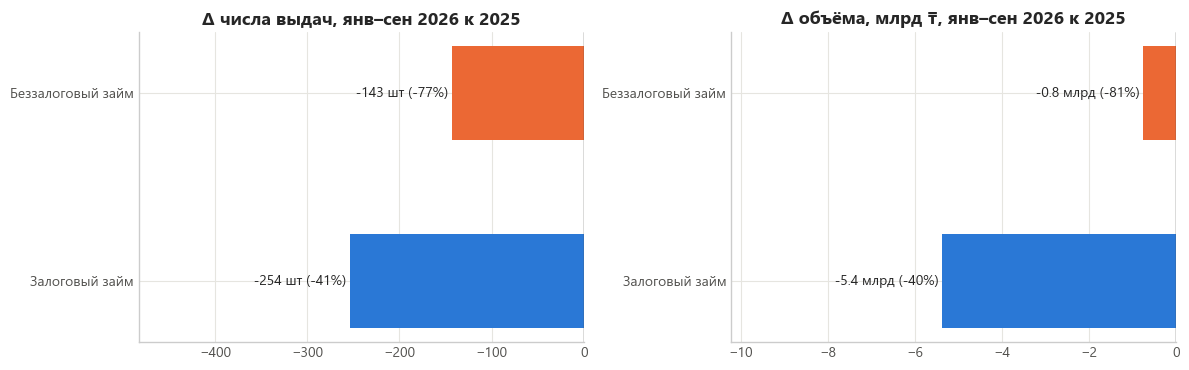

In [15]:
# H2. Где потеряли сделки: залоговые vs беззалоговые (янв–сен 2026 к янв–сен 2025).
# Канал/партнёр указан не во всех заявках, поэтому делим только по продукту — он заполнен всегда.
x = df[(df.month <= 9) & df.year.isin([2025, 2026])]
pp = x.groupby(["product", "year"], observed=True).agg(n=("loan_id", "size"), amt=("amount_kzt", "sum")).unstack()
prod_delta = pd.DataFrame({
    "выдач 2025": pp["n"][2025], "выдач 2026": pp["n"][2026],
    "Δ выдач": pp["n"][2026] - pp["n"][2025], "Δ выдач, %": pp["n"][2026] / pp["n"][2025] - 1,
    "Δ объёма, млрд ₸": bn(pp["amt"][2026] - pp["amt"][2025]), "Δ объёма, %": pp["amt"][2026] / pp["amt"][2025] - 1,
})
prod_delta["доля потерянных выдач"] = prod_delta["Δ выдач"] / prod_delta["Δ выдач"].sum()
prod_delta["доля потерянного объёма"] = prod_delta["Δ объёма, млрд ₸"] / prod_delta["Δ объёма, млрд ₸"].sum()
chi = stats.chi2_contingency(pp["n"].values)
mix = pp["n"].loc["Беззалоговый займ"] / pp["n"].sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, col, fmt, ttl in [(ax[0], "Δ выдач", "{:+.0f} шт ({:+.0%})", "Δ числа выдач"),
                         (ax[1], "Δ объёма, млрд ₸", "{:+.1f} млрд ({:+.0%})", "Δ объёма, млрд ₸")]:
    vals = prod_delta[col].reindex(list(PAL))
    pct_col = "Δ выдач, %" if col == "Δ выдач" else "Δ объёма, %"
    a.barh(vals.index, vals.values, color=list(PAL.values()), height=.5)
    for k, (v, p) in enumerate(zip(vals, prod_delta[pct_col].reindex(list(PAL)))):
        a.text(v, k, " " + fmt.format(v, p) + " ", va="center", ha="right", fontsize=10)
    a.axvline(0, color="#52514e", lw=1); a.set_xlim(vals.min() * 1.9, 0)
    a.set_title(f"{ttl}, янв–сен 2026 к 2025")
plt.tight_layout(); fig.savefig(IMG / "08b_drivers.png", dpi=150, bbox_inches="tight")
print(f"Доля беззалоговых в выдачах: 2025 — {mix[2025]:.0%}, 2026 — {mix[2026]:.0%}; "
      f"χ² = {chi[0]:.1f}, p = {chi[1]:.1e}")
prod_delta.T.round(3)

**Вывод: H2 подтверждена частично.** Беззалоговые займы почти исчезли: −77% выдач, их доля упала с 23% до 10% (χ², p < 0,001). Но залоговые тоже упали на 41%, и именно они дают **64% потерянных сделок и 88% потерянного объёма** (−5,4 из −6,1 млрд ₸). В пересчёте на менеджера: залоговых 12,0 → 6,4 в месяц, беззалоговых 3,6 → 0,7. То есть по деньгам главная проблема — залоговый поток, а беззалог — по количеству клиентов.

### 5.2 Retention и ramp-up менеджеров (когорты)

Нанято в наблюдаемом периоде: 23 менеджеров
Средний объём новичка по месяцу работы (6 = 6+): 1: 200, 2: 239, 3: 230, 4: 212, 5: 271, 6: 252 млн ₸


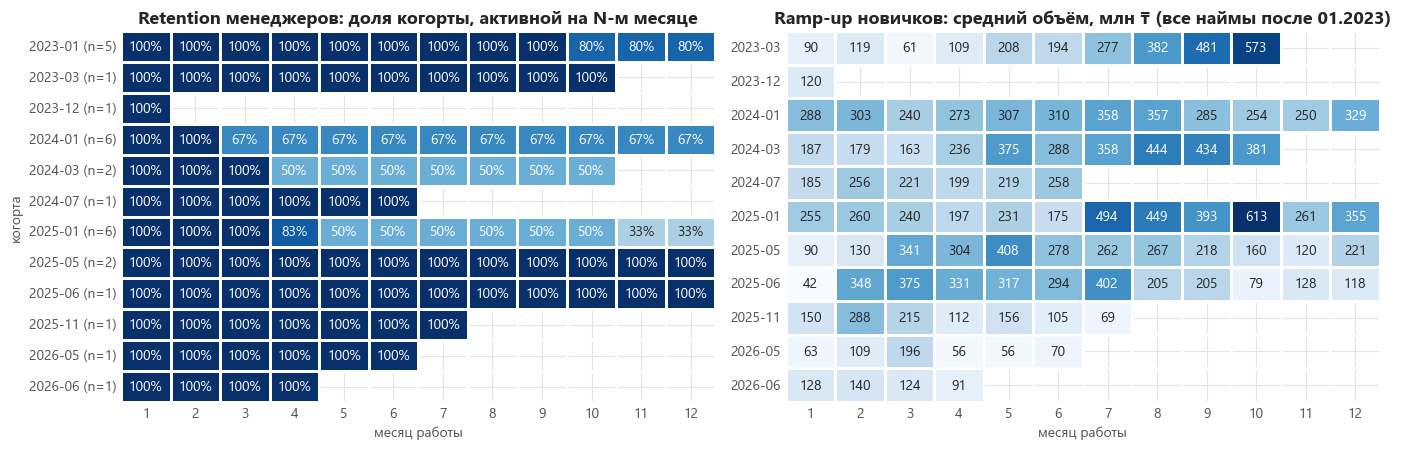

In [16]:
coh = sq.run("manager_cohorts")
size = coh[coh.tenure_month == 1].set_index("cohort_ym").active_managers
coh["retention"] = coh.active_managers / coh.cohort_ym.map(size)
ret = coh.pivot(index="cohort_ym", columns="tenure_month", values="retention").iloc[:, :12]
# когорта 2023-01 — это менеджеры, работавшие до начала данных (стаж неизвестен), её в ramp-up не берём
ramp = coh[coh.cohort_ym > "2023-01"].pivot(index="cohort_ym", columns="tenure_month", values="avg_amount_kzt").iloc[:, :12]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(ret, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax[0], cbar=False, linewidths=2, linecolor="white",
            yticklabels=[f"{c} (n={size[c]})" for c in ret.index])
ax[0].set(title="Retention менеджеров: доля когорты, активной на N-м месяце", xlabel="месяц работы", ylabel="когорта")
sns.heatmap(mln(ramp), annot=True, fmt=".0f", cmap="Blues", ax=ax[1], cbar=False, linewidths=2, linecolor="white")
ax[1].set(title="Ramp-up новичков: средний объём, млн ₸ (все наймы после 01.2023)", xlabel="месяц работы", ylabel="")
plt.tight_layout(); fig.savefig(IMG / "09_cohorts.png", dpi=150, bbox_inches="tight")

panel = mm.copy()
first_ym = panel.groupby("manager_id").ym.min()
hires = first_ym[first_ym > "2023-01"].index            # нанятые в наблюдаемом периоде (стаж известен с 1-го месяца)
by_t = panel[panel.manager_id.isin(hires)].assign(t=lambda d: np.minimum(d.tenure_month, 6)).groupby("t").amount_kzt.mean()
print(f"Нанято в наблюдаемом периоде: {len(hires)} менеджеров")
print("Средний объём новичка по месяцу работы (6 = 6+):",
      ", ".join(f"{t}: {mln(v):.0f}" for t, v in by_t.items()), "млн ₸")

**Вывод:** есть два типа найма.
- **Январская смена команды (2024 и 2025 годы):** менеджеры с 1-го месяца выдают на уровне опытных (медиана ≈265 млн ₸ за первые 2 месяца). Похоже, это опытные специалисты или переводы.
- **Найм в течение года по одному:** 1-й месяц ≈130 млн ₸, 2-й ≈160 млн ₸, к **3-му месяцу** — уровень команды. Каждый такой найм стоит ≈2 месяцев недовыдачи.

Retention: ни один менеджер 2023 и 2024 годов не проработал больше года (команда менялась целиком). Январская когорта 2025 года к 5-му месяцу потеряла половину (3 из 6), а майская и июньская когорты 2025 года держатся больше года.

### 5.3 LTV, CAC и ROI менеджера (сценарный расчёт)
В выгрузке нет ставок, маржи и затрат на персонал, поэтому **LTV клиента и маркетинговый CAC посчитать нельзя**. Вместо этого считаем юнит-экономику менеджера при явных допущениях; их нужно заменить на данные финансовой службы.

In [17]:
# LTV-аналог для команды продаж: накопленный объём менеджера за первые N месяцев
p = panel.sort_values(["manager_id", "tenure_month"]).copy()
p["cum_bn"] = bn(p.groupby("manager_id").amount_kzt.cumsum())
p = p[p.manager_id.isin(hires)]
ltv = p.pivot_table(index="tenure_month", values="cum_bn", aggfunc=["mean", "count"]).loc[[3, 6, 12]]
ltv.columns = ["накопленный объём, млрд ₸ (среднее)", "менеджеров дожили"]

# Сценарная юнит-экономика менеджера. ДОПУЩЕНИЯ — заменить на данные финансов банка.
ASSUMPTIONS = {
    "Годовая чистая маржа, залоговый": 0.035,   # доля от суммы выдачи за 1-й год
    "Годовая чистая маржа, беззалоговый": 0.09,
    "Полная стоимость менеджера в месяц, ₸": 900_000,
    "Стоимость найма и онбординга (CAC менеджера), ₸": 1_500_000,
}
m_sec = ASSUMPTIONS["Годовая чистая маржа, залоговый"]; m_uns = ASSUMPTIONS["Годовая чистая маржа, беззалоговый"]
amt_by = df.pivot_table(index=["manager_id", "ym"], columns="product", values="amount_kzt",
                                         aggfunc="sum", fill_value=0, observed=True)
income = amt_by["Залоговый займ"] * m_sec + amt_by["Беззалоговый займ"] * m_uns
mgr_income = income.groupby("manager_id").agg(["sum", "size"])
mgr_income["cost"] = mgr_income["size"] * ASSUMPTIONS["Полная стоимость менеджера в месяц, ₸"] + \
                     ASSUMPTIONS["Стоимость найма и онбординга (CAC менеджера), ₸"]
mgr_income["ROI"] = (mgr_income["sum"] - mgr_income["cost"]) / mgr_income["cost"]
mgr_income["payback_days"] = 30 * ASSUMPTIONS["Стоимость найма и онбординга (CAC менеджера), ₸"] / (
    mgr_income["sum"] / mgr_income["size"] - ASSUMPTIONS["Полная стоимость менеджера в месяц, ₸"])
print("Допущения сценария:"); [print(f"  {k}: {v:,}") for k, v in ASSUMPTIONS.items()]
print(f"Медианный ROI менеджера: {mgr_income.ROI.median():.1f}x; "
      f"менеджеров с ROI < 0: {(mgr_income.ROI < 0).sum()} из {len(mgr_income)}")
ltv

Допущения сценария:
  Годовая чистая маржа, залоговый: 0.035
  Годовая чистая маржа, беззалоговый: 0.09
  Полная стоимость менеджера в месяц, ₸: 900,000
  Стоимость найма и онбординга (CAC менеджера), ₸: 1,500,000
Медианный ROI менеджера: 6.8x; менеджеров с ROI < 0: 0 из 28


,"накопленный объём, млрд ₸ (среднее)",менеджеров дожили
tenure_month,,
3,0.66,20
6,1.41,15
12,3.00,9


In [18]:
mgr_income.rename(columns={"sum": "доход_₸", "size": "месяцев"}).assign(
    доход_млн=lambda d: mln(d["доход_₸"]), затраты_млн=lambda d: mln(d.cost))[
    ["месяцев", "доход_млн", "затраты_млн", "ROI", "payback_days"]].sort_values("ROI", ascending=False).round(1)

,месяцев,доход_млн,затраты_млн,ROI,payback_days
manager_id,,,,,
MGR_004,10,172.40,10.50,15.40,2.80
MGR_016,12,162.90,12.30,12.20,3.50
MGR_014,7,102.00,7.80,12.10,3.30
MGR_015,12,157.50,12.30,11.80,3.70
MGR_020,10,124.00,10.50,10.80,3.90
MGR_018,12,125.60,12.30,9.20,4.70
MGR_003,4,51.60,5.10,9.10,3.70
MGR_030,10,106.10,10.50,9.10,4.60
MGR_024,12,119.80,12.30,8.70,5.00


**Вывод:** за 12 месяцев менеджер выдаёт в среднем ≈3 млрд ₸, но до 12-го месяца доживают только 9 из 20 нанятых. Даже при консервативной марже найм окупается за дни, и у всех 28 менеджеров ROI > 0. Управленческий вывод: **дорого не нанять, а потерять менеджера**. Уход сильного сотрудника и 2 месяца разгона замены стоят сотни миллионов ₸ выдач. Слабейшие по ROI — новички 2026 года (MGR_012, MGR_013), которые пришли в «сухой» рынок, и MGR_031, проработавший 1 месяц.

### 5.4 Retention клиентов: повторные обращения (январь–сентябрь 2025)

Клиентов янв–сен 2025: 636; вернулись повторно: 142 (22.3%)
Повторные выдачи: 175 из 811 (21.6% всех выдач янв–сен 2025)
Медианный интервал до 2-го займа: 52 дней; возврат за 90 дней: 25.4%
2-й займ у того же менеджера: 20%; у другого: 80%
Суммарно за период: повторный клиент — медиана 35.1 млн ₸, разовый — 16.0 млн ₸


2-й займ,Беззалоговый займ,Залоговый займ
1-й займ,,
Беззалоговый займ,11,25
Залоговый займ,30,76


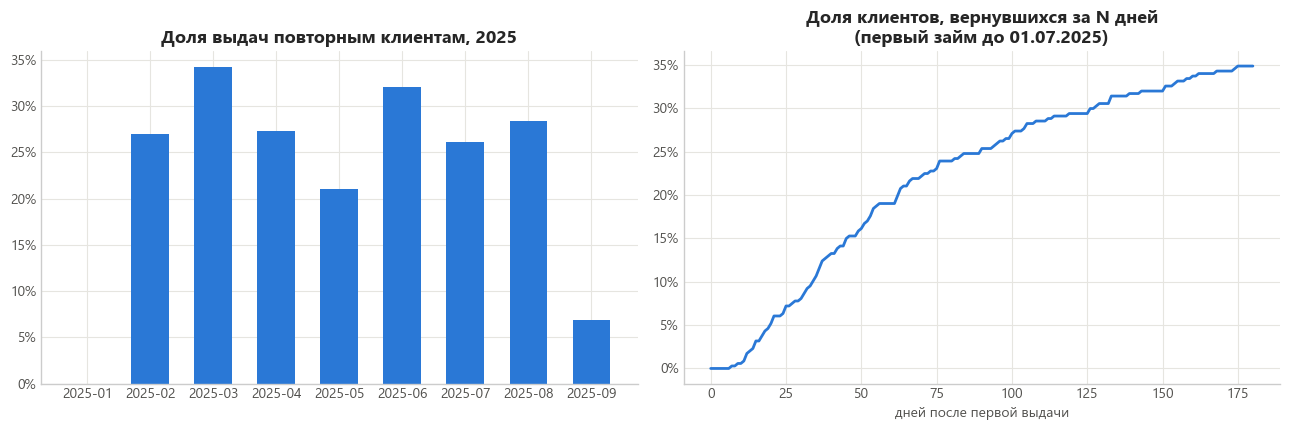

In [19]:
# Повторные обращения клиентов (видны в январе–сентябре 2025, см. проверку ID в §3)
w = df[(df.ym >= pd.Period("2025-01", "M")) & (df.ym <= pd.Period("2025-09", "M"))].sort_values(["client_id", "issue_date"]).copy()
w["k"] = w.groupby("client_id").cumcount() + 1
w["gap_days"] = (w.issue_date - w.groupby("client_id").issue_date.shift()).dt.days
w["same_mgr"] = w.manager_id.astype(str) == w.groupby("client_id").manager_id.shift().astype(str)
cl = w.groupby("client_id").agg(loans=("loan_id", "size"), amount=("amount_kzt", "sum"),
                                first=("issue_date", "min"), first_product=("product", "first"))
rep_cl = cl[cl.loans > 1]
second = w[w.k == 2]
rep_share_m = w.assign(rep=w.k > 1).groupby("ym").rep.mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].bar(rep_share_m.index.astype(str), rep_share_m.values, color="#2a78d6", width=.6)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[0].set(title="Доля выдач повторным клиентам, 2025")
# кривая возврата: доля клиентов, взявших 2-й займ в течение N дней (только те, у кого было ≥ 90 дней окна)
base = cl[cl["first"] <= pd.Timestamp("2025-07-01")]
gaps = second.set_index("client_id").gap_days.reindex(base.index)
days = np.arange(0, 181)
curve = [(gaps <= t).mean() for t in days]
ax[1].plot(days, curve, color="#2a78d6")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[1].set(title="Доля клиентов, вернувшихся за N дней\n(первый займ до 01.07.2025)", xlabel="дней после первой выдачи")
plt.tight_layout(); fig.savefig(IMG / "09b_clients.png", dpi=150, bbox_inches="tight")

print(f"Клиентов янв–сен 2025: {len(cl):,}; вернулись повторно: {len(rep_cl)} ({len(rep_cl) / len(cl):.1%})")
print(f"Повторные выдачи: {int((w.k > 1).sum())} из {len(w)} ({(w.k > 1).mean():.1%} всех выдач янв–сен 2025)")
print(f"Медианный интервал до 2-го займа: {second.gap_days.median():.0f} дней; возврат за 90 дней: {(gaps <= 90).mean():.1%}")
print(f"2-й займ у того же менеджера: {second.same_mgr.mean():.0%}; у другого: {1 - second.same_mgr.mean():.0%}")
print(f"Суммарно за период: повторный клиент — медиана {mln(rep_cl.amount.median()):.1f} млн ₸, "
      f"разовый — {mln(cl[cl.loans == 1].amount.median()):.1f} млн ₸")
pd.crosstab(cl.loc[second.client_id, "first_product"].values, second["product"].values,
            rownames=["1-й займ"], colnames=["2-й займ"])

**Вывод:** в январе–сентябре 2025 года **22% клиентов вернулись за повторным займом**, и это дало **22% всех выдач** (175 из 811). Медианный интервал до второго займа — 52 дня; за 90 дней возвращается четверть клиентов, за полгода — около трети. Повторный клиент приносит за период в 2,2 раза больше разового (35 против 16 млн ₸). Главная проблема: **80% повторных займов клиент оформил у другого менеджера**, то есть клиент «ничей», за ним никто не закреплён.

**Дополнительная находка — связь с падением 2026 года:** с октября 2025 года повторных выдач в данных нет вообще. Если клиенты действительно перестали возвращаться, только это объясняет ≈175 из 397 потерянных сделок (44%), и это пересекается с сегментами из §5.1, а не добавляется к ним. Если же выгрузка просто перестала связывать клиентов, вывод не подтверждается. Это нужно сверить с первоисточником.

<a id="6"></a>
## 6. Прогноз: линейная регрессия
### Модель A — от чего зависит сумма выдачи

Модель A — R² на log-шкале: 0.45; MAE: 8.1 млн ₸ при медианной выдаче 17.9 млн
Залог сам по себе увеличивает сумму в 5.0 раза; каждый год даёт +8.7% к сумме


,"эффект, %"
канал: Под собственный залог,-22.00
канал: Вторичное жильё,-21.00
канал: Цифровая ипотека (ЦИ),-11.00
канал: Стандарт (без партнёра),-4.40
канал: Прочее / нераспознано,-0.50
4 квартал,5.30
канал: Беззалоговый: БЗК/рефинанс,7.00
канал: Партнёр-застройщик,8.40
каждый следующий год,8.70
выходной день,8.90


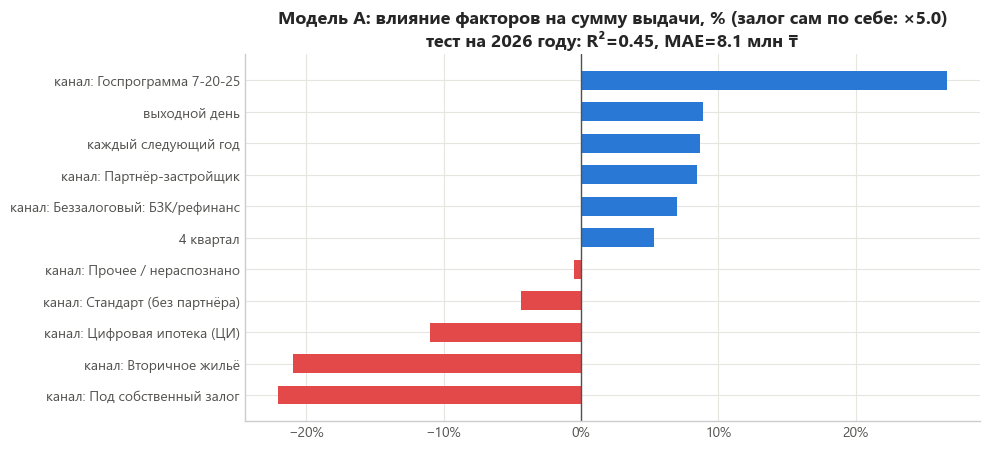

In [20]:
# Модель A: что определяет сумму выдачи? Цель — log(сумма), коэффициенты читаются как % эффекта.
X = pd.get_dummies(df[["channel"]], drop_first=False, dtype=int).drop(columns="channel_Не указано")
X["secured"] = df.is_secured
X["year_idx"] = df.year - 2023
X["q4"] = df.month.isin([10, 11, 12]).astype(int)
X["weekend"] = df.is_weekend.astype(int)
y = np.log(df.amount_kzt)
trm, tem = df.year <= 2025, df.year == 2026          # обучение 2023–2025, тест 2026
mA = LinearRegression().fit(X[trm], y[trm])
predA = np.exp(mA.predict(X[tem]))
r2A = r2_score(y[tem], mA.predict(X[tem]))
maeA = mean_absolute_error(df.amount_kzt[tem], predA) / 1e6
effects = (np.exp(pd.Series(mA.coef_, index=X.columns)) - 1).sort_values()
effects.index = (effects.index.str.replace("channel_", "канал: ")
                 .str.replace("year_idx", "каждый следующий год").str.replace("q4", "4 квартал")
                 .str.replace("weekend", "выходной день").str.replace("secured", "залоговый продукт"))
e_plot = effects.drop("залоговый продукт")
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(e_plot.index, e_plot.values, color=["#2a78d6" if v > 0 else "#e34948" for v in e_plot.values], height=.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.axvline(0, color="#52514e", lw=1)
ax.set(title=f"Модель A: влияние факторов на сумму выдачи, % (залог сам по себе: ×{1 + effects['залоговый продукт']:.1f})\n"
             f"тест на 2026 году: R²={r2A:.2f}, MAE={maeA:.1f} млн ₸")
plt.tight_layout(); fig.savefig(IMG / "10_regression.png", dpi=150, bbox_inches="tight")
print(f"Модель A — R² на log-шкале: {r2A:.2f}; MAE: {maeA:.1f} млн ₸ при медианной выдаче {df.amount_mln[tem].median():.1f} млн")
print(f"Залог сам по себе увеличивает сумму в {np.exp(mA.coef_[list(X.columns).index('secured')]):.1f} раза; "
      f"каждый год даёт {effects['каждый следующий год']:+.1%} к сумме")
(effects * 100).round(1).to_frame("эффект, %")

**Вывод:** на отложенном 2026 году модель объясняет 45% вариации log(суммы), MAE = 8 млн ₸. Наличие залога увеличивает сумму в 5 раз. Через застройщика сделка на ≈8% крупнее, через госпрограмму 7-20-25 — на ≈27%, вторичка и «свой залог» дают на ≈20% меньше. Тренд: +9% к чеку в год.

### Модель B — объём менеджера в следующем месяце

In [21]:
# Цель: объём менеджера в следующем месяце (млн ₸). Панель с заполнением пропущенных месяцев нулями.
mm["t"] = pd.PeriodIndex(mm.ym, freq="M")
team = mm.groupby("t").manager_id.nunique().rename("team_size")
rows = []
for m, g in mm.groupby("manager_id"):
    idx = pd.period_range(g.t.min(), g.t.max(), freq="M")
    g = g.set_index("t").reindex(idx)
    g["manager_id"] = m
    g[["cnt", "amount_kzt", "cnt_secured"]] = g[["cnt", "amount_kzt", "cnt_secured"]].fillna(0)
    g["tenure"] = np.arange(1, len(g) + 1)
    rows.append(g)
P = pd.concat(rows).rename_axis("t").reset_index()
P["amt"] = mln(P.amount_kzt)
P = P.join(team, on="t")
P["amt_lag1"] = P.amt
P["amt_roll3"] = P.groupby("manager_id").amt.transform(lambda s: s.rolling(3, min_periods=1).mean())
P["cnt_lag1"] = P.cnt
P["secured_share"] = (P.cnt_secured / P.cnt.replace(0, np.nan)).fillna(0)
P["log_tenure"] = np.log(P.tenure)
P["next_m"] = (P.t + 1).dt.month
P["sin_m"], P["cos_m"] = np.sin(2 * np.pi * P.next_m / 12), np.cos(2 * np.pi * P.next_m / 12)
P["is_july_dec"] = P.next_m.isin([7, 12]).astype(int)
P["target"] = P.groupby("manager_id").amt.shift(-1)
P = P.dropna(subset=["target"])
P = P[P.t < pd.Period("2026-09", "M")]       # целевой октябрь 2026 неполный — исключаем
FEATS = ["amt_lag1", "amt_roll3", "cnt_lag1", "secured_share", "log_tenure", "team_size", "sin_m", "cos_m"]
split = pd.Period("2025-09", "M")              # обучаем на прошлом, тестируем на последних 13 месяцах
tr, te = P[P.t < split], P[P.t >= split]
print(f"Обучение: {len(tr)} наблюдений ({tr.t.min()}…{tr.t.max()}), тест: {len(te)} ({te.t.min()}…{te.t.max()})")

Обучение: 171 наблюдений (2023-01…2025-08), тест: 74 (2025-09…2026-08)


Лучшая модель по MAE: Наивный: = среднее 3 мес (74 млн ₸ на менеджера)


,R²,"MAE, млн ₸"
"LinearRegression, 8 признаков",-0.01,116.06
"LinearRegression, лаг + среднее 3 мес",0.34,86.23
Наивный: = прошлый месяц,0.34,86.00
Наивный: = среднее 3 мес,0.53,74.28


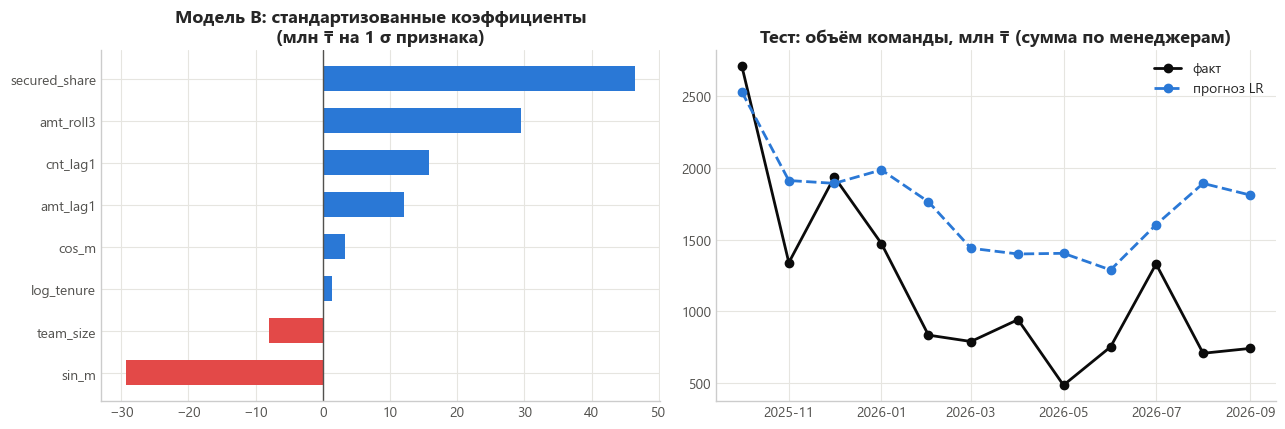

In [22]:
models = {"LinearRegression, 8 признаков": FEATS, "LinearRegression, лаг + среднее 3 мес": ["amt_lag1", "amt_roll3"]}
res, fitted = {}, {}
for name, f in models.items():
    sc = StandardScaler().fit(tr[f])
    m = LinearRegression().fit(sc.transform(tr[f]), tr.target)
    p = m.predict(sc.transform(te[f])).clip(0)
    fitted[name] = (m, f, p)
    res[name] = (r2_score(te.target, p), mean_absolute_error(te.target, p))
for name, base in {"Наивный: = прошлый месяц": te.amt_lag1, "Наивный: = среднее 3 мес": te.amt_roll3}.items():
    res[name] = (r2_score(te.target, base), mean_absolute_error(te.target, base))
res = pd.DataFrame(res, index=["R²", "MAE, млн ₸"]).T

m8, f8, p8 = fitted["LinearRegression, 8 признаков"]
coef = pd.Series(m8.coef_, index=f8).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].barh(coef.index, coef.values, color=["#2a78d6" if v > 0 else "#e34948" for v in coef.values], height=.6)
ax[0].axvline(0, color="#52514e", lw=1)
ax[0].set(title="Модель B: стандартизованные коэффициенты\n(млн ₸ на 1 σ признака)")
monthly_te = te.assign(pred=p8).groupby("t")[["target", "pred"]].sum()
ax[1].plot(monthly_te.index.to_timestamp() + pd.offsets.MonthBegin(1), monthly_te.target, color="#0b0b0b", marker="o", label="факт")
ax[1].plot(monthly_te.index.to_timestamp() + pd.offsets.MonthBegin(1), monthly_te.pred, color="#2a78d6", marker="o", ls="--", label="прогноз LR")
ax[1].set(title="Тест: объём команды, млн ₸ (сумма по менеджерам)"); ax[1].legend()
plt.tight_layout(); fig.savefig(IMG / "11_forecast.png", dpi=150, bbox_inches="tight")
print(f"Лучшая модель по MAE: {res['MAE, млн ₸'].idxmin()} ({res['MAE, млн ₸'].min():.0f} млн ₸ на менеджера)")
res.round(3)

**Вывод (отрицательный результат — тоже результат):** линейная регрессия на 8 признаках **проигрывает** простому «среднему за 3 месяца» (MAE 116 против 74 млн ₸). Модель обучена на 2023–2025 годах и не знает о структурном сломе 2026 года: она систематически завышает прогноз (правый график). Для планирования лучше использовать скользящее среднее за 3 месяца с пересчётом каждый месяц.

In [23]:
# Ориентир на октябрь 2026 по лучшему подходу (среднее 3 мес по каждому активному менеджеру)
act = mm[mm.ym == "2026-09"].manager_id
roll = mm[mm.ym.between("2026-07", "2026-09") & mm.manager_id.isin(act)].groupby("manager_id").amount_kzt.sum() / 3
oct_fact = mm[mm.ym == "2026-10"].amount_kzt.sum()
wd_oct = pd.bdate_range("2026-10-01", "2026-10-31"); wd_done = pd.bdate_range("2026-10-01", "2026-10-12")
print(f"Ориентир на октябрь 2026: {mln(roll.sum()):,.0f} млн ₸ (±{res.loc['Наивный: = среднее 3 мес','MAE, млн ₸'] * len(roll):,.0f} млн)")
print(f"Факт за 1–12 октября: {mln(oct_fact):,.0f} млн ₸ → run-rate на месяц ≈ {mln(oct_fact) * len(wd_oct) / len(wd_done):,.0f} млн ₸")

Ориентир на октябрь 2026: 926 млн ₸ (±520 млн)
Факт за 1–12 октября: 337 млн ₸ → run-rate на месяц ≈ 928 млн ₸


**Проверка здравым смыслом:** ориентир на октябрь (≈0,93 млрд ₸) совпадает с темпом первых 12 дней месяца. Это меньше половины октября 2025 года (2,7 млрд ₸): без вмешательства 4 квартал повторит 2026 год, а не 2025-й.

### 6.3 Прогноз выдач на 4 квартал 2026
Прогнозируем объём команды на октябрь–декабрь. Сначала проверяем три метода на истории: «прогнозируем» 4 квартал 2025 года, зная данные только по сентябрь 2025.

In [24]:
# Помесячный объём команды, млн ₸ (октябрь 2026 неполный — в обучение не берём)
S = (df.groupby("ym").amount_kzt.sum() / 1e6)
S_full = S[S.index <= pd.Period("2026-09", "M")]
Q3 = lambda y: S_full[pd.Period(f"{y}-07", "M"):pd.Period(f"{y}-09", "M")].mean()

def seasonal_index(series):
    """Классический индекс сезонности: отношение к центрированной 2×12 скользящей средней."""
    ma = series.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
    r = (series / ma).dropna()
    si = r.groupby(r.index.month).mean().reindex(range(1, 13)).fillna(1)
    return si / si.mean()

def q4_ratio(years):
    """Сколько каждый месяц 4 квартала составляет от среднего июля–сентября того же года."""
    return pd.DataFrame({y: [S_full[pd.Period(f"{y}-{m}", "M")] / Q3(y) for m in (10, 11, 12)] for y in years},
                        index=[10, 11, 12])

# Бэктест: прогнозируем 4 кв. 2025 года, зная данные только по сентябрь 2025
hist = S_full[S_full.index <= pd.Period("2025-09", "M")]
si = seasonal_index(hist)
lvl = (hist.iloc[-3:] / si.loc[[7, 8, 9]].values).mean()
bt = pd.DataFrame({
    "факт": [S_full[pd.Period(f"2025-{m}", "M")] for m in (10, 11, 12)],
    "A. среднее 3 мес": [hist.iloc[-3:].mean()] * 3,
    "B. индекс сезонности (2023–2025)": [lvl * si[m] for m in (10, 11, 12)],
    "C. Q4/Q3 прошлого года (2024)": (Q3(2025) * q4_ratio([2024])[2024]).values,
}, index=["окт 2025", "ноя 2025", "дек 2025"])
bt.loc["4 кв. итого"] = bt.sum()
err = (bt.drop(columns="факт").loc["4 кв. итого"] / bt.loc["4 кв. итого", "факт"] - 1)
mape = (bt.drop(index="4 кв. итого").drop(columns="факт").sub(bt["факт"].drop("4 кв. итого"), axis=0).abs()
          .div(bt["факт"].drop("4 кв. итого"), axis=0).mean())
print("Ошибка прогноза суммы 4 кв. 2025:", ", ".join(f"{k}: {v:+.0%}" for k, v in err.items()))
print("Средняя помесячная ошибка (MAPE):", ", ".join(f"{k}: {v:.0%}" for k, v in mape.items()))
bt.round(0)

Ошибка прогноза суммы 4 кв. 2025: A. среднее 3 мес: +17%, B. индекс сезонности (2023–2025): +34%, C. Q4/Q3 прошлого года (2024): +8%
Средняя помесячная ошибка (MAPE): A. среднее 3 мес: 32%, B. индекс сезонности (2023–2025): 49%, C. Q4/Q3 прошлого года (2024): 30%


,факт,A. среднее 3 мес,B. индекс сезонности (2023–2025),C. Q4/Q3 прошлого года (2024)
окт 2025,"2,710.00","2,389.00","2,441.00","2,091.00"
ноя 2025,"1,490.00","2,389.00","2,566.00","2,085.00"
дек 2025,"1,936.00","2,389.00","3,195.00","2,465.00"
4 кв. итого,"6,136.00","7,168.00","8,202.00","6,641.00"


**Вывод:** лучше всех сработал метод C — «4 квартал как доля от июля–сентября прошлого года»: ошибка по кварталу +8%, по месяцам ≈30%. Классический индекс сезонности (B) переоценил квартал на 34%. Причина в том, что в 2023 году объём рос втрое и 4 квартал того года отражает рост, а не сезонность. Помесячная точность у любого метода низкая (±30%), поэтому **планировать стоит по кварталу, а не по отдельным месяцам**.

Отношения 4 кв. к среднему июля–сентября (2024 / 2025): 10: 0.88 / 1.13, 11: 0.87 / 0.62, 12: 1.03 / 0.81
Прогноз 4 кв. 2026: 2.48 млрд ₸ (диапазон 2.14–2.81); 4 кв. 2025 — 6.14 млрд ₸ (-60%)
Проверка октября: прогноз 931 млн ₸, темп первых 12 дней ≈ 928 млн ₸
Год 2026 целиком ≈ 10.7 млрд ₸ против 20.5 млрд ₸ в 2025 (-48%)


,прогноз,нижняя граница,верхняя граница,факт 2025
месяц,,,,
окт 2026,931.00,811.00,"1,051.00","2,710.00"
ноя 2026,693.00,578.00,808.00,"1,490.00"
дек 2026,853.00,751.00,956.00,"1,936.00"


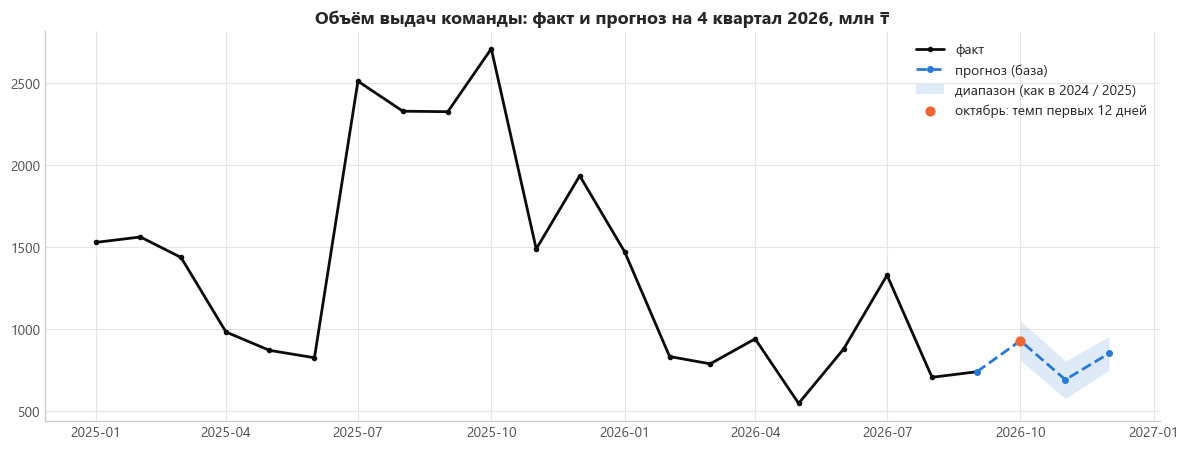

In [25]:
# Метод C: 4 квартал = среднее июля–сентября 2026 × типичное отношение месяцев 4 кв. к 3 кв.
# Отношения берём по 2024 и 2025 годам: в 2023 году команда набирала обороты (объём вырос втрое),
# и его 4 квартал отражает рост, а не сезонность.
ratios = q4_ratio([2024, 2025])
base_q3 = Q3(2026)
fc = pd.DataFrame({
    "месяц": ["окт 2026", "ноя 2026", "дек 2026"],
    "прогноз": base_q3 * ratios.mean(axis=1).values,
    "нижняя граница": base_q3 * ratios.min(axis=1).values,
    "верхняя граница": base_q3 * ratios.max(axis=1).values,
    "факт 2025": [S_full[pd.Period(f"2025-{m}", "M")] for m in (10, 11, 12)],
}).set_index("месяц")
q4 = fc.sum()
oct_rr = mln(df[df.ym == pd.Period("2026-10", "M")].amount_kzt.sum()) * len(pd.bdate_range("2026-10-01", "2026-10-31")) \
         / len(pd.bdate_range("2026-10-01", "2026-10-12"))
fy26 = bn(df[(df.year == 2026) & (df.month <= 9)].amount_kzt.sum()) + q4["прогноз"] / 1e3
fy25 = bn(df[df.year == 2025].amount_kzt.sum())

fig, ax = plt.subplots(figsize=(12, 4.6))
h = S_full[S_full.index >= pd.Period("2025-01", "M")]
ax.plot(h.index.to_timestamp(), h.values, color="#0b0b0b", marker="o", markersize=3, label="факт")
fx = pd.period_range("2026-10", "2026-12", freq="M").to_timestamp()
ax.plot([h.index[-1].to_timestamp(), *fx], [h.values[-1], *fc["прогноз"]], color="#2a78d6", marker="o",
        markersize=4, ls="--", label="прогноз (база)")
ax.fill_between(fx, fc["нижняя граница"], fc["верхняя граница"], color="#2a78d6", alpha=.15, lw=0,
                label="диапазон (как в 2024 / 2025)")
ax.plot(pd.period_range("2025-10", "2025-12", freq="M").to_timestamp(), fc["факт 2025"], color="#a8a7a0", lw=0)
ax.scatter([fx[0]], [oct_rr], color="#eb6834", zorder=5, s=40, label="октябрь: темп первых 12 дней")
ax.set(title="Объём выдач команды: факт и прогноз на 4 квартал 2026, млн ₸")
ax.legend(loc="upper right")
plt.tight_layout(); fig.savefig(IMG / "12_q4_forecast.png", dpi=150, bbox_inches="tight")

print(f"Отношения 4 кв. к среднему июля–сентября (2024 / 2025): " +
      ", ".join(f"{m}: {ratios.loc[m, 2024]:.2f} / {ratios.loc[m, 2025]:.2f}" for m in ratios.index))
print(f"Прогноз 4 кв. 2026: {q4['прогноз'] / 1e3:.2f} млрд ₸ (диапазон {q4['нижняя граница'] / 1e3:.2f}–"
      f"{q4['верхняя граница'] / 1e3:.2f}); 4 кв. 2025 — {q4['факт 2025'] / 1e3:.2f} млрд ₸ "
      f"({q4['прогноз'] / q4['факт 2025'] - 1:+.0%})")
print(f"Проверка октября: прогноз {fc.iloc[0, 0]:,.0f} млн ₸, темп первых 12 дней ≈ {oct_rr:,.0f} млн ₸")
print(f"Год 2026 целиком ≈ {fy26:.1f} млрд ₸ против {fy25:.1f} млрд ₸ в 2025 ({fy26 / fy25 - 1:+.0%})")
fc.round(0)

**Вывод:** базовый прогноз (если ничего не менять) — **≈2,5 млрд ₸ за 4 квартал 2026** (диапазон 2,1–2,8). Это на 60% меньше, чем в 4 квартале 2025 года (6,1 млрд ₸). Прогноз октября (931 млн ₸) совпадает с фактическим темпом первых 12 дней (≈928 млн ₸), то есть метод «попадает» в текущий уровень. **Год 2026 целиком ≈ 10,7 млрд ₸ против 20,5 млрд ₸ в 2025 году (−48%).** Ноябрь, как и в прошлые годы, будет самым слабым месяцем квартала.

### 6.4 Сценарии: что изменит план действий

                                                выдач в месяц  средний чек, млн ₸  + млн ₸ в месяц (полный эффект)
1. Беззалог — к темпу 2025                              15.90                5.00                            79.90
2. Залоговые — закрыть половину разрыва с 2025          14.10               21.50                           303.60
3. Повторные клиенты — половина потока 2025              9.70               16.90                           164.30

4 кв.: база 2.48 млрд ₸ → все три шага 3.30 млрд ₸; декабрь со всеми шагами 1,401 млн ₸
Внимание: поток 3 частично пересекается с 1 и 2 (повторный займ тоже бывает залоговым или беззалоговым).


,База,+ беззалог,+ залоговые,+ повторные клиенты
месяц,,,,
окт 2026,931.00,931.00,931.00,931.00
ноя 2026,693.00,733.00,885.00,967.00
дек 2026,853.00,933.00,"1,237.00","1,401.00"
4 кв. итого,"2,477.00","2,597.00","3,052.00","3,299.00"


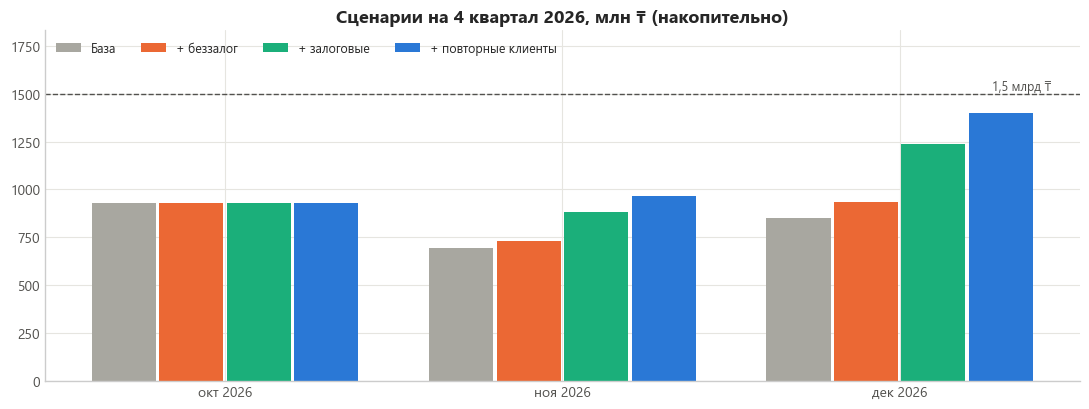

In [26]:
# Сценарии: что даст возврат каждого из потерянных потоков к темпу янв–сен 2025.
# Октябрь уже идёт — эффект с ноября: ноябрь 50% (разгон), декабрь 100%.
RAMP = {"окт 2026": 0.0, "ноя 2026": 0.5, "дек 2026": 1.0}
y25 = df[(df.year == 2025) & (df.month <= 9)]; y26 = df[(df.year == 2026) & (df.month <= 9)]
def gap(mask25, mask26):
    """Разница в выдачах в месяц и средний чек потока в 2025 году."""
    return (mask25.sum() - mask26.sum()) / 9, y25.loc[mask25, "amount_kzt"].mean() / 1e6
unsec = gap(y25["product"] == "Беззалоговый займ", y26["product"] == "Беззалоговый займ")
sec = gap(y25["product"] == "Залоговый займ", y26["product"] == "Залоговый займ")
sec_half = (sec[0] / 2, sec[1])                       # реалистично — закрыть половину разрыва
rep_loans_m = (w.k > 1).sum() / 9
rep_ticket = w.loc[w.k > 1, "amount_kzt"].mean() / 1e6
levers = pd.DataFrame({
    "выдач в месяц": [unsec[0], sec_half[0], rep_loans_m / 2],
    "средний чек, млн ₸": [unsec[1], sec_half[1], rep_ticket],
}, index=["1. Беззалог — к темпу 2025", "2. Залоговые — закрыть половину разрыва с 2025",
          "3. Повторные клиенты — половина потока 2025"])
levers["+ млн ₸ в месяц (полный эффект)"] = levers["выдач в месяц"] * levers["средний чек, млн ₸"]

scen = pd.DataFrame({"База": fc["прогноз"]})
acc = fc["прогноз"].copy()
for name, add in zip(["+ беззалог", "+ залоговые", "+ повторные клиенты"],
                     levers["+ млн ₸ в месяц (полный эффект)"]):
    acc = acc + add * pd.Series(RAMP)
    scen[name] = acc
scen.loc["4 кв. итого"] = scen.sum()

fig, ax = plt.subplots(figsize=(11, 4.2))
cols = ["#a8a7a0", "#eb6834", "#1baf7a", "#2a78d6"]
x = np.arange(3)
for i, (c, col) in enumerate(zip(scen.columns, cols)):
    ax.bar(x + (i - 1.5) * .2, scen[c].iloc[:3], width=.19, color=col, label=c)
ax.axhline(1500, color="#52514e", ls="--", lw=1); ax.text(2.45, 1520, "1,5 млрд ₸", ha="right", fontsize=9, color="#52514e")
ax.set_xticks(x, scen.index[:3]); ax.set(title="Сценарии на 4 квартал 2026, млн ₸ (накопительно)")
ax.set_ylim(0, max(1500, scen.iloc[:3].values.max()) * 1.22)
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.tight_layout(); fig.savefig(IMG / "13_q4_scenarios.png", dpi=150, bbox_inches="tight")
print(levers.round(1).to_string())
print(f"\n4 кв.: база {scen.loc['4 кв. итого', 'База'] / 1e3:.2f} млрд ₸ → все три шага "
      f"{scen.loc['4 кв. итого'].iloc[-1] / 1e3:.2f} млрд ₸; декабрь со всеми шагами {scen.iloc[2, -1]:,.0f} млн ₸")
print("Внимание: поток 3 частично пересекается с 1 и 2 (повторный займ тоже бывает залоговым или беззалоговым).")
scen.round(0)

**Вывод:** самый большой рычаг — залоговые займы: закрыть хотя бы половину разрыва с 2025 годом (≈14 сделок в месяц) — это ≈+300 млн ₸ в месяц. Беззалог даёт немного денег (+80 млн ₸ в месяц), зато возвращает поток клиентов. Если запустить все три шага с ноября, 4 квартал вырастет с 2,5 до **≈3,3 млрд ₸**, а **декабрь выйдет на ≈1,4 млрд ₸**. Сценарий 3 частично пересекается с 1 и 2, поэтому итог — верхняя оценка.

In [27]:
hist_out = S_full[S_full.index >= pd.Period("2025-01", "M")].rename("amount_mln").reset_index()
hist_out["kind"] = "факт"; hist_out["ym"] = hist_out.ym.astype(str)
fc_out = scen.iloc[:3].copy()
fc_out["lo"] = fc["нижняя граница"].values; fc_out["hi"] = fc["верхняя граница"].values
fc_out.index = ["2026-10", "2026-11", "2026-12"]
fc_out = fc_out.rename(columns={"База": "base", "+ беззалог": "s1", "+ залоговые": "s2",
                                "+ повторные клиенты": "s3"}).rename_axis("ym").reset_index()
fc_out.round(1).to_csv(ROOT / "data" / "processed" / "forecast_q4_2026.csv", index=False)
hist_out.round(1).to_csv(ROOT / "data" / "processed" / "monthly_total.csv", index=False)
print("Сохранено: forecast_q4_2026.csv, monthly_total.csv")

Сохранено: forecast_q4_2026.csv, monthly_total.csv


<a id="7"></a>
## 7. Проверка гипотез (α = 0.05)

In [28]:
ALPHA = 0.05
def verdict(p): return "Различие значимо" if p < ALPHA else "Различие случайно (H0 не отвергаем)"

a = df[(df["product"] == "Залоговый займ") & (df.year == 2025)].amount_mln
b = df[(df["product"] == "Залоговый займ") & (df.year == 2026)].amount_mln
u = stats.mannwhitneyu(a, b, alternative="two-sided")
t = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)
print(f"H1. Медиана залоговой выдачи: 2025 — {a.median():.1f} млн, 2026 — {b.median():.1f} млн")
print(f"    Манн-Уитни p={u.pvalue:.4f}; t-тест Уэлча на log(суммы) p={t.pvalue:.4f} → {verdict(u.pvalue)}")

H1. Медиана залоговой выдачи: 2025 — 19.1 млн, 2026 — 19.1 млн
    Манн-Уитни p=0.5332; t-тест Уэлча на log(суммы) p=0.4773 → Различие случайно (H0 не отвергаем)


In [29]:
# Новички, нанятые в течение года по одному (не в составе январской смены команды)
mid_hires = [m for m in hires if not str(first_ym[m]).endswith("-01")]
jan_hires = [m for m in hires if str(first_ym[m]).endswith("-01")]
for name, grp in [("январская смена команды", jan_hires), ("найм в течение года", mid_hires)]:
    s1 = panel[panel.manager_id.isin(grp) & (panel.tenure_month <= 2)].amount_kzt
    print(f"   {name}: медиана первых 2 месяцев {mln(s1.median()):.0f} млн ₸ (n={len(s1)})")
new = mln(panel[panel.manager_id.isin(mid_hires) & (panel.tenure_month <= 2)].amount_kzt)
old = mln(panel[panel.tenure_month > 3].amount_kzt)
u2 = stats.mannwhitneyu(new, old, alternative="less")
print(f"H2. Найм в течение года, первые 2 месяца — медиана {new.median():.0f} млн (n={len(new)}), "
      f"далее — {old.median():.0f} млн (n={len(old)})")
print(f"    Манн-Уитни (односторонний, новички < опытных) p={u2.pvalue:.4f} → {verdict(u2.pvalue)}")

   январская смена команды: медиана первых 2 месяцев 266 млн ₸ (n=24)
   найм в течение года: медиана первых 2 месяцев 145 млн ₸ (n=21)
H2. Найм в течение года, первые 2 месяца — медиана 145 млн (n=21), далее — 218 млн (n=193)
    Манн-Уитни (односторонний, новички < опытных) p=0.0007 → Различие значимо


In [30]:
c = clean.copy()
def wd_share(row):
    days = pd.date_range(row.issue_date.replace(day=1), periods=row.days_in_month)
    wd = days[days.dayofweek < 5]
    return (wd.day > row.days_in_month - 5).sum() / len(wd)
exp_share = c.drop_duplicates("ym").set_index("ym").apply(wd_share, axis=1)
expected = c.ym.map(exp_share).mean()
k, n = int(c.is_last5.sum()), len(c)
bt = stats.binomtest(k, n, expected, alternative="greater")
print(f"H3. В последние 5 дней месяца: {k / n:.1%} выдач при ожидаемых {expected:.1%} (по доле рабочих дней)")
print(f"    Биномиальный тест p={bt.pvalue:.4f} → {'Эффект «дожима плана» есть' if bt.pvalue < ALPHA else 'Эффекта «дожима плана» нет'}")

H3. В последние 5 дней месяца: 16.1% выдач при ожидаемых 16.5% (по доле рабочих дней)
    Биномиальный тест p=0.7683 → Эффекта «дожима плана» нет


In [31]:
s = df[df["product"] == "Залоговый займ"]
dv = s[s.channel == "Партнёр-застройщик"].amount_mln; st = s[s.channel == "Стандарт (без партнёра)"].amount_mln
u4 = stats.mannwhitneyu(dv, st, alternative="two-sided")
print(f"H4. Залоговый чек: через застройщика — медиана {dv.median():.1f} млн (n={len(dv)}), "
      f"стандарт — {st.median():.1f} млн (n={len(st)})")
print(f"    Манн-Уитни p={u4.pvalue:.4f} → {verdict(u4.pvalue)}")

H4. Залоговый чек: через застройщика — медиана 19.4 млн (n=1572), стандарт — 17.4 млн (n=436)
    Манн-Уитни p=0.0000 → Различие значимо


### H3. Сезонность

H3. 2026 ниже 2025 в 8 из 9 месяцев; медиана разрыва -45%; в сезонный пик (июль–сентябрь) -61%
    Сезонный подъём июль–сентябрь к январю–июню: 2023: ×2.38, 2024: ×1.21, 2025: ×1.99, 2026: ×1.02
    Уилкоксон (парный, по месяцам) p=0.0059; знаковый тест p=0.0195 → 2026 значимо ниже 2025 в те же месяцы — спад не сезонный


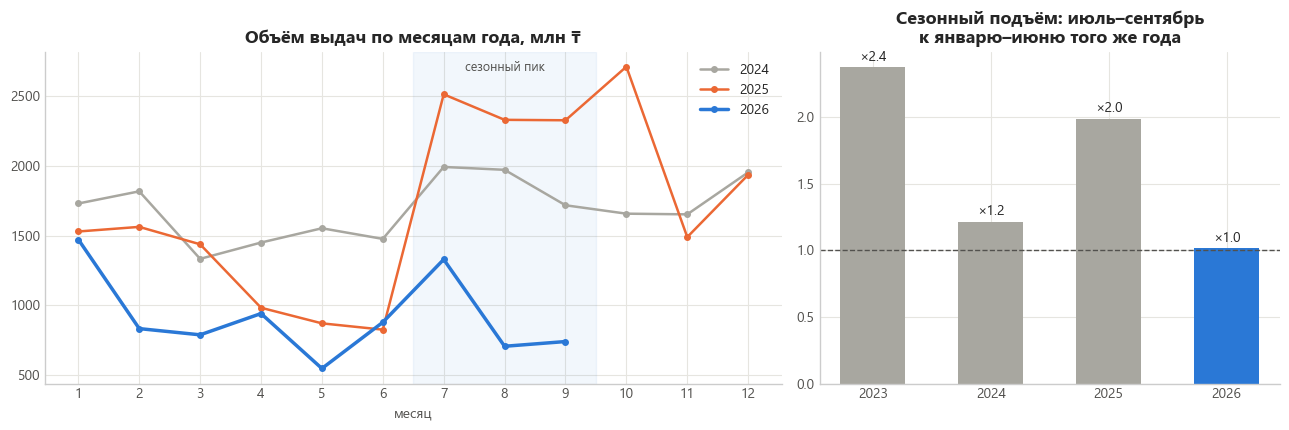

In [32]:
# H3. «Спад 2026 года — это сезонность: первое полугодие всегда слабое, рост придёт во втором»
M = df[df.ym <= pd.Period("2026-09", "M")].groupby(["year", "month"]).amount_kzt.sum().unstack(0) / 1e6
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
for y, col in zip([2024, 2025, 2026], ["#a8a7a0", "#eb6834", "#2a78d6"]):
    ax[0].plot(M.index, M[y], marker="o", markersize=4, color=col, label=str(y), lw=2.5 if y == 2026 else 1.8)
ax[0].axvspan(6.5, 9.5, color="#2a78d6", alpha=.06)
ax[0].text(8, ax[0].get_ylim()[1] * .95, "сезонный пик", ha="center", fontsize=9, color="#52514e")
ax[0].set(title="Объём выдач по месяцам года, млн ₸", xticks=range(1, 13), xlabel="месяц")
ax[0].legend()
lift = pd.Series({y: M.loc[7:9, y].mean() / M.loc[1:6, y].mean() for y in [2023, 2024, 2025, 2026]})
ax[1].bar(lift.index.astype(str), lift.values, color=["#a8a7a0"] * 3 + ["#2a78d6"], width=.55)
ax[1].axhline(1, color="#52514e", lw=1, ls="--")
for i, v in enumerate(lift.values):
    ax[1].text(i, v + .05, f"×{v:.1f}", ha="center", fontsize=10)
ax[1].set(title="Сезонный подъём: июль–сентябрь\nк январю–июню того же года")
plt.tight_layout(); fig.savefig(IMG / "05b_seasonality_test.png", dpi=150, bbox_inches="tight")

d26 = M.loc[1:9, 2026] / M.loc[1:9, 2025] - 1
w_ = stats.wilcoxon(M.loc[1:9, 2026], M.loc[1:9, 2025], alternative="less")
sign = stats.binomtest(int((d26 < 0).sum()), 9, 0.5, alternative="greater")
print(f"H3. 2026 ниже 2025 в {(d26 < 0).sum()} из 9 месяцев; медиана разрыва {d26.median():+.0%}; "
      f"в сезонный пик (июль–сентябрь) {M.loc[7:9, 2026].sum() / M.loc[7:9, 2025].sum() - 1:+.0%}")
print(f"    Сезонный подъём июль–сентябрь к январю–июню: " + ", ".join(f"{y}: ×{v:.2f}" for y, v in lift.items()))
print(f"    Уилкоксон (парный, по месяцам) p={w_.pvalue:.4f}; знаковый тест p={sign.pvalue:.4f} → "
      f"{'2026 значимо ниже 2025 в те же месяцы — спад не сезонный' if w_.pvalue < ALPHA else 'различие случайно'}")

**Вывод: H3 отвергнута — спад не сезонный.** 2026 год ниже 2025-го в 8 из 9 сопоставимых месяцев, медианный разрыв −45% (тест Уилкоксона p = 0,006, знаковый тест p = 0,02). Единственное исключение — июнь, когда 2025 год сам был в провале. Главное — в 2026 году **не случилось сезонного подъёма**: в 2024 и 2025 годах июль–сентябрь были в 1,2–2 раза сильнее первого полугодия, а в 2026-м — на уровне первого полугодия. Даже в пиковые месяцы объём на 61% ниже прошлого года. Значит, ждать, что «второе полугодие вытянет», нельзя.

| Гипотеза | Тест | Итог |
|---|---|---|
| Залоговый чек 2026 ≠ 2025 | Манн-Уитни, Уэлч на log | **случайно**: чек не изменился, проблема не в нём |
| Новички, нанятые в течение года, в первые 2 месяца выдают меньше | Манн-Уитни (одностор.) | **значимо**: медиана 145 против 218 млн ₸; январская смена команды стартует сразу на уровне опытных |
| «Дожим» плана в конце месяца | Биномиальный | **не подтверждена**: выдачи равномерны |
| Сделки через застройщика крупнее | Манн-Уитни | **значимо**: медиана 19,4 млн ₸ против 17,4 млн ₸ |
| **H3.** Спад сезонный | Уилкоксон (парный), знаковый | **отвергнута**: 2026 ниже 2025 в 8 из 9 месяцев (p = 0,006), сезонного подъёма нет |

In [33]:
# Выгрузка витрин для дашборда
out = ROOT / "data" / "processed"
mk.to_csv(out / "monthly_kpi.csv", index=False)
mm.drop(columns=["t"]).to_csv(out / "manager_month.csv", index=False)
df.drop(columns=["client_surname_synth"]).assign(ym=df.ym.astype(str)).to_csv(out / "loans_clean.csv", index=False)
print("Сохранено:", ", ".join(p.name for p in out.glob("*.csv")))

Сохранено: forecast_q4_2026.csv, loans_clean.csv, manager_month.csv, monthly_kpi.csv, monthly_total.csv


<a id="8"></a>
## 8. Дашборд
Дашборд собирается в Power BI. Таблицы модели «звезда» выгружает `src/export_powerbi.py` (данные этого ноутбука и прогноз из §6.3–6.4), а DAX-меры и раскладка страниц описаны в `powerbi/README.md`.

<a id="9"></a>
## 9. Выводы и рекомендации: что делать бизнесу завтра

**Диагноз:** команда не уменьшилась и стала опытнее, сделки не стали мельче, но у каждого менеджера стало вдвое меньше сделок. Беззалоговые займы почти исчезли (−77%), но по деньгам главная потеря — залоговые (−41% выдач, 88% потерянного объёма). Сезонного подъёма во втором полугодии не было.

1. **Разобраться, куда ушли залоговые сделки, — это 88% потерянных денег.** У менеджера стало 6,4 залоговых сделки в месяц против 12,0 в 2025 году. С партнёрским отделом и менеджерами нужно пройти источники залоговых сделок (застройщики, вторичка, «свой залог») и вернуть хотя бы половину разрыва: ≈14 сделок в месяц ≈ **+0,3 млрд ₸ в месяц**.
2. **Вернуть поток беззалоговых займов.** Совместно с риск-менеджментом выяснить, что изменилось (политика, лимиты, скоринг). Возврат к темпу 2025 года (≈16 сделок в месяц × 5 млн ₸) даёт +0,08 млрд ₸ в месяц, но главное — поток новых клиентов и кросс-продажу к залогу.
3. **Начать заполнять продукт и партнёра в каждой заявке.** Сейчас в ≈30% выдач канал не указан, поэтому нельзя точно сказать, какие источники сделок пропали. Без этого поля следующий спад снова придётся разбирать вслепую.
4. **Вернуть повторных клиентов и закрепить их за менеджерами.** В 2025 году каждый пятый клиент возвращался в среднем через 52 дня, но в 80% случаев к другому менеджеру. Нужны закрепление клиента за менеджером, обзвон через 30–60 дней после выдачи и учёт повторных выдач в мотивации. Восстановление хотя бы половины потока 2025 года даёт ≈10 сделок в месяц (≈0,2 млрд ₸).
5. **Удерживать менеджеров, а не перенабирать.** Штат ограничен 7 ставками, поэтому объём растёт только за счёт продуктивности и удержания, а не найма. Команда дважды менялась целиком, топ-2 менеджера дают 36–41% объёма, а новичок в течение года теряет около 2 месяцев на разгон. Нужны мотивация за стаж и наставник для новичков; вакансию закрывать заранее, особенно перед июльским пиком.
6. **Планировать по скользящему среднему за 3 месяца и сезонности.** Июль, август и октябрь — пик: ресурсы и маркетинг партнёров стоит готовить к ним заранее. Прогноз на 4 квартал без изменений — ≈2,5 млрд ₸ (−60% к 2025 году). Шаги 1, 2 и 4, запущенные с ноября, дают ≈3,3 млрд ₸ и выводят декабрь на ≈1,4 млрд ₸ (§6.4).